# Originally made by Dominic Hildebrand
For the wine project working under Chrats Melkonian. 

Yeah so uhh... Good luck making sense of this chaos. 
I really tried to do my best to keep it somewhat managable with 
comments and such, but it went completely out of hand. 

Date this text was written: 20-7-2025

In [2]:
version

               _                                
platform       x86_64-w64-mingw32               
arch           x86_64                           
os             mingw32                          
crt            ucrt                             
system         x86_64, mingw32                  
status                                          
major          4                                
minor          5.0                              
year           2025                             
month          04                               
day            11                               
svn rev        88135                            
language       R                                
version.string R version 4.5.0 (2025-04-11 ucrt)
nickname       How About a Twenty-Six           

# First we try to get a PCA going

In [3]:
if (!require("BiocManager", quietly = TRUE))
    install.packages("BiocManager")

BiocManager::install("mixOmics")
library(mixOmics) 
library(tidyr)
library(dplyr)
library("proxy")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.21 (BiocManager 1.30.25), R 4.5.0 (2025-04-11 ucrt)

Warning message:
"package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'mixOmics'"
Installation paths not writeable, unable to update packages
  path: C:/Program Files/R/R-4.5.0/library
  packages:
    lattice, mgcv

Old packages: 'BiocManager', 'BiocParallel', 'broom', 'commonmark', 'curl',
  'data.table', 'DEoptimR', 'evaluate', 'glmnet', 'httr2', 'limma', 'pillar',
  'pkgbuild', 'promises', 'purrr', 'Rcpp', 'RcppArmadillo', 'rgl', 'rprojroot',
  'shiny', 'tibble', 'utf8', 'waldo'

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.32.0
Thank you for using mixOmics!
Tutorials: http://mixomics.

In [4]:
# data <- read.csv("all_samples_summary_genus.tsv", header = TRUE, sep="\t")
# data = read.csv("kaiju_summary_complete_genus.tsv", row.names = 1, header = TRUE, sep="\t")
data = read.csv("kaiju_summary_complete_genus.tsv", header = TRUE, sep="\t")
# paste(data$genus, data$taxon_id, sep = "_")
rownames(data) <- paste(data$genus, data$taxon_id, sep = "_")
# data <- data[-c("unclassified"), ]

data <- dplyr::select(data, -c('taxon_id', "phylum", "class", "order", "family", "genus","species"))


# colnames(data) <- sub("^.", "", colnames(data))
# colnames(data) <- sub("^([^\\.]+\\..*?)\\..*", "\\1", colnames(data))
data <- data[row.names(data) != "_unclassified",]


head(data)
# "unclassified" %in% row.names(data)

,X4.04a..on..14.10,X6.06a..2.5..06.10,X3.wgt01..5b..08.11,X1.01a..press2..13.10,X15.07a..2.5..05.10,X10.wgt07.775.5..09.10,X7.02a..6.0..15.10,X1.05b..sed..29.10,X6.wgt04..3...75,X2.wgt03...10..30.12,⋯,X7.04b..4.0..16.10,X5.01a..on..19.10,X7.wgt07.202.43b..07.10,X12.B7..library..neg,X6.05c..11..07.11,X1.18b..2.5..15.10,X1.01a..press1..13.10,X4.04c..6.0..17.10,X10.01b..11..28.10,X2.wgt04..b4su..17.10
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
Saccharomyces_4930,2568331,11033577,20104452,179130,13401388,7832124,21730335,112167,26758575,25399354,⋯,9735323,12169678,10095232,7,34137639,83448331,122451,8354401,37734978,12091
Hanseniaspora_29832,1059970,7902,11305857,3268302,353068,101727,232742,582870,892960,613550,⋯,26139,1538180,431242,20,36878,5604985,2185914,54769,636978,3052541
Ralstonia_48736,665855,145316,571041,719057,121239,11347,143872,2178735,1819823,283867,⋯,79153,221205,33824,366,149340,246009,857199,82915,143751,843465
Aureobasidium_5579,143115,311583,30289,5598216,154600,39752,67155,3932179,424833,57160,⋯,72172,183964,263077,0,113732,608215,12785642,87257,83033,124617
Pseudomonas_286,109923,32914,85512,51001,75087,29802,31394,168242,626444,244282,⋯,55989,5834,68408,2055,15868,161624,110743,74401,18401,546591
Burkholderia_32008,75974,29732,99005,115079,31609,3498,26372,356077,293062,54953,⋯,15642,32266,8234,554,35345,59901,119456,16147,39285,171482


# The following code block regards normalization
Normalization does several things, but the results are not too different 
either way.

In [5]:
data <- as.data.frame(scale(data))
# data

In [6]:
sub("^([^\\.]+\\..*?)\\..*", "\\1", colnames(data))

[1] "X4.04a"            "X6.06a"            "X3.wgt01"         
  [4] "X1.01a"            "X15.07a"           "X10.wgt07"        
  [7] "X7.02a"            "X1.05b"            "X6.wgt04"         
 [10] "X2.wgt03"          "X2.04b"            "X1.02c"           
 [13] "raw.V300063189"    "X3.wgt05"          "X3.wgt02"         
 [16] "X4.01c"            "X1.wgt03b"         "X9.B8"            
 [19] "X4.05c"            "X1.17b"            "X16.B9"           
 [22] "X8.03c"            "X7.06c"            "X1.wgt03"         
 [25] "X3.wgt07"          "X5.wgt02"          "X12.07a"          
 [28] "X13.B9"            "X10.07b"           "X5.03b"           
 [31] "X3.wgt04"          "X11.06a"           "X2.01c"           
 [34] "raw.V300063189"    "X1.04b"            "X3.05c"           
 [37] "X17.07a"           "X1.wgt01"          "raw.V300063189"   
 [40] "X7.04a"            "X4.wgt05"          "X1.18a"           
 [43] "X6.wgt07"          "X2.02b"            "X2.wgt03"         
 [46] "X4.05a"            "X1.wgt05"          "X1.03c"           
 [49] "X8.05a"            "X6.wgt04"          "X8.06c"           
 [52] "X14.07a"           "raw.V300063189"    "X8.02a"           
 [55] "X2.wgt06"          "X1.wgt01"          "X10.01a"          
 [58] "X18.07a"           "X3.02a"            "X1.03c"           
 [61] "X5.06c"            "X4.wgt04"          "X13.07b"          
 [64] "X5.wgt06"          "X2.wgt07"          "X5.03c"           
 [67] "X4.B7"             "CB.CL100066028"    "X11.01a"          
 [70] "X2.05b"            "X5.05c"            "X1.03a"           
 [73] "X7.05c"            "X9.01a"            "X1.B1"            
 [76] "raw.V300063189"    "X4.01a"            "X2.03c"           
 [79] "X3.03a"            "X1.wgt07"          "X7.wgt04"         
 [82] "X8.01a"            "X13.07a"           "X8.B8"            
 [85] "X6.wgt06"          "X1.wgt02"          "X1.wgt04"         
 [88] "X11.wgt07"         "X10.wgt07"         "X6.04a"           
 [91] "X10.04a"           "X1.wgt01"          "raw.V300063189"   
 [94] "X7.03a"            "X19.B1"            "X7.B2"            
 [97] "X9.04b"            "X4.wgt02"          "X3.06c"           
[100] "X12.07c"           "X5.B5"             "X5.03a"           
[103] "X7.03b"            "X3.04a"            "X9.02a"           
[106] "X2.02b"            "X2.02c"            "X1.06a"           
[109] "X1.01c"            "X8.03b"            "X5.wgt01"         
[112] "X8.04a"            "X1.wgt01"          "X9.03b"           
[115] "CB.CL100066028"    "X2.05b"            "X4.wgt05"         
[118] "X2.wgt05"          "raw.V300063189"    "X2.04c"           
[121] "X4.06b"            "X1.07a"            "X4.wgt02"         
[124] "X1.05a"            "X2.07b"            "raw.V300063189"   
[127] "X7.01c"            "CB.CL100066028"    "raw.V300063189"   
[130] "X4.wgt07"          "X2.03b"            "X4.05b"           
[133] "X6.02c"            "raw.V300063189"    "X7.01a"           
[136] "X4.03b"            "X3.wgt02"          "X9.07c"           
[139] "X14.B3"            "X5.02c"            "X10.07c"          
[142] "X3.06b"            "X9.07b"            "raw.V300063189"   
[145] "X7.05b"            "X9.06a"            "X8.04b"           
[148] "X8.07b"            "X6.05b"            "X3.wgt06"         
[151] "X17.B2"            "X5.01c"            "X3.B6"            
[154] "X8.01b"            "X1.wgt06press209b" "X4.02c"           
[157] "X10.04b"           "X11.04b"           "raw.V300063189"   
[160] "X3.wgt04"          "X5.05a"            "X3.03b"           
[163] "X2.wgt01"          "X5.01b"            "X4.02b"           
[166] "X6.wgt07"          "X13.07c"           "X1.06b"           
[169] "X1.02b"            "X3.wgt05"          "X11.07c"          
[172] "X3.01c"            "X3.05a"            "X5.02a"           
[175] "X7.wgt06"          "X7.02c"            "X8.03a"           
[178] "X1.wgt05"          "X10.06a"           "X2.01b"           
[181] "X1.05c"            "X3.06b"        

In [7]:
pca_avgs <- prcomp(na.omit(t(data)), scale=TRUE)
# pca_avgs$rotation <- -1*pca_avgs$rotation
head(pca_avgs$rotation)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,⋯,PC310,PC311,PC312,PC313,PC314,PC315,PC316,PC317,PC318,PC319
Saccharomyces_4930,0.008416968,-0.004380606,0.023922335,-0.006499898,-0.0017304551,0.003880161,0.01100899,0.020094646,-0.021429700,0.001795800,⋯,0.013456532,0.011489379,0.0229234128,-0.009776435,-0.004514730,0.002336342,0.014443288,0.0011154456,-0.016693120,-0.10174158
Hanseniaspora_29832,-0.002182664,0.007261755,-0.006333674,-0.001551844,-0.0003198905,0.025209486,-0.01695897,0.028610064,-0.003680382,0.009122878,⋯,0.015876991,-0.023546843,0.0335759190,0.008775745,0.010364335,0.001027167,0.005245087,0.0040688244,0.014719031,-0.07863293
Ralstonia_48736,-0.007020086,0.010502614,-0.031065299,-0.003808524,-0.0006731968,0.057703350,-0.06155666,-0.052422128,-0.033219421,0.010139888,⋯,-0.002839431,0.002257662,-0.0073874885,-0.014635846,0.001439930,0.004489775,-0.019140558,0.0028302805,-0.009323943,-0.05377651
Aureobasidium_5579,-0.007100184,0.036624486,-0.046429880,-0.010360832,-0.0008299116,-0.009984071,0.02957898,-0.021532662,-0.007104442,-0.007720109,⋯,-0.019482309,0.011185608,-0.0069552086,0.002089010,0.011232237,0.018211720,-0.010986581,0.0066416781,-0.030440221,-0.16655107
Pseudomonas_286,-0.006246213,0.002614385,0.005961076,0.021790606,0.0155186491,-0.012197265,-0.03288260,0.017391214,0.009790559,0.035964008,⋯,-0.049698180,-0.004495024,-0.1019744618,0.043702952,0.029404909,-0.005166271,0.015991331,-0.0477599977,0.041512124,-0.00513057
Burkholderia_32008,-0.005382390,-0.064747974,-0.024425577,-0.010898484,-0.0004208321,-0.009686146,0.01535069,-0.003817499,-0.002646572,0.001713603,⋯,0.005033536,-0.003882839,0.0006602917,-0.008117662,0.003604081,-0.007351778,0.011525195,0.0004188727,0.003232111,0.07692115


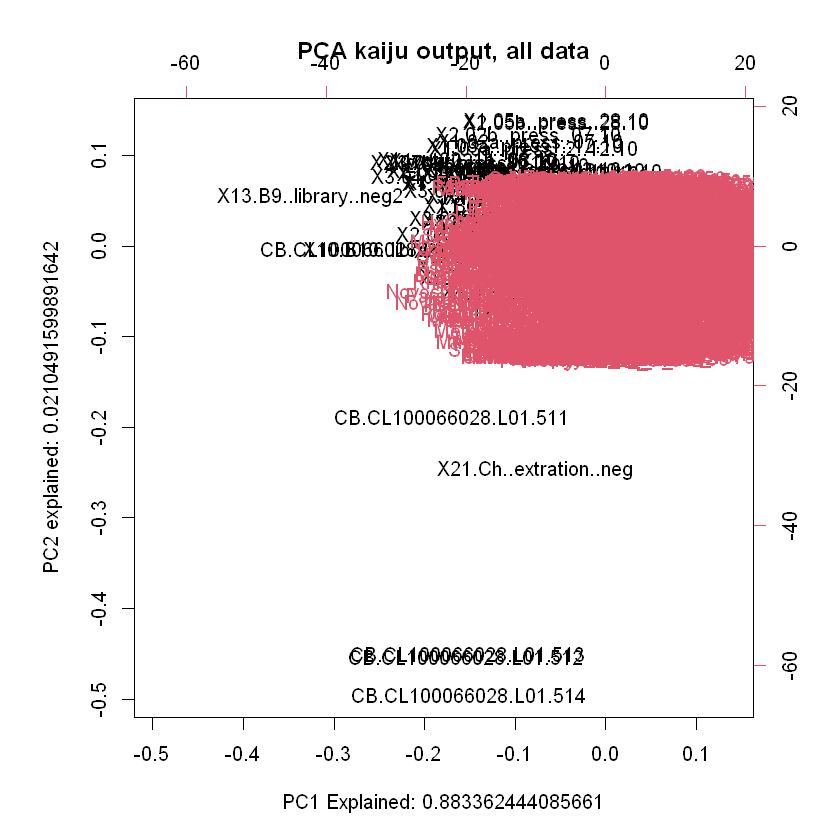

In [8]:
stdeviations <- pca_avgs$sdev^2 / sum(pca_avgs$sdev^2)
# stdeviations
biplot(pca_avgs, xlab = paste("PC1 Explained:", stdeviations[1]),
        ylab = paste("PC2 explained:", stdeviations[2]))
        
title("PCA kaiju output, all data")

In [9]:
# data = read.csv("all_samples_summary_genus.tsv", row.names = 1, header = TRUE, sep="\t")
# # data = read.csv("kaiju_summary_complete_genus.tsv", row.names = 1, header = TRUE, sep="\t")
# # data[row.names(data) != "Bacteria", , drop = FALSE]

# is_integer <- function(x) {
#   return(is.numeric(x) && x == as.integer(x))
# }

# # Keep rows where all values are integers, including row names
# data <- data[sapply(data, function(x) all(sapply(x, is_integer)) & grepl("^[0-9]+$", rownames(data))), ]


# pca_avgs <- prcomp(na.omit(data), scale=TRUE)
# stdeviations <- pca_avgs$sdev^2 / sum(pca_avgs$sdev^2)
# # stdeviations
# biplot(pca_avgs, xlab = paste("PC1 Explained:", stdeviations[1]),
#         ylab = paste("PC2 explained:", stdeviations[2]))
        
# title("PCA kaiju output, no 'unclassified'")


# PCA

Was not super succesful. Hence, we try to connect the different datatypes 
together into a comprehensive analysis

In [10]:
df_flavour_avgs <- read.csv2("df_avgs.tsv", sep="\t")
# df_flavour_avgs <- read.csv2("df_avgs.tsv", sep="\t", row.names = "X")

df_flavour_avgs <- df_flavour_avgs %>% mutate_if(is.character, as.numeric)
head(df_flavour_avgs) 

,color,fruity_odor,lemon,apple.peach,exotic,oxidized_apple,green,floral,honey,smoky,microbiological,fruity_taste,sweet,sour,body,mouthfeel,bitter
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,3.027500,4.622500,3.847500,4.085000,4.097500,3.485000,4.092500,3.857500,2.872500,3.730000,3.000000,5.222500,4.145000,4.637500,5.042500,5.107500,3.260000
01b,2.933333,4.317949,4.258974,4.594872,4.671795,3.064103,3.410256,3.505128,3.112821,3.417949,2.817949,5.633333,3.615385,5.553846,4.515385,5.453846,3.202564
01c,3.037500,3.655000,3.402500,3.162500,3.937500,3.005000,3.485000,3.380000,2.572500,3.590000,3.275000,4.887500,3.537500,5.347500,4.812500,4.822500,3.510000
02a,3.470000,5.227500,4.692500,4.190000,5.045000,3.297500,4.355000,4.107500,3.020000,3.712500,2.605000,5.592500,4.532500,3.845000,5.345000,4.400000,3.702500
02b,3.572500,5.632500,4.435000,4.505000,4.387500,3.262500,3.760000,4.530000,3.020000,2.785000,2.147500,5.335000,4.322500,4.302500,5.450000,4.282500,3.405000
02c,3.497500,4.647500,3.387500,3.865000,3.522500,2.792500,3.655000,3.650000,2.715000,3.632500,3.187500,5.560000,4.635000,4.107500,5.000000,3.845000,3.285000


In [11]:
df_species_genus <- read.csv2("filterlist_genus.tsv", sep="\t")
head(df_species_genus)

,phylum,X01a.01..press1..13.10,X01a.01..press2..13.10,X01a.04..sed..14.10,X01a.05..on..19.10,X01a.06..2.5..20.10,X01a.07..4.0..21.10,X01a.08..6.0..23.10,X01a.09..8..24.10,X01a.10..11..28.10,⋯,wgt07.06.775.53..06.10,wgt07.07.202.43b..07.10,wgt07.07.775.32..07.10,wgt07.08.202.43..07.10,wgt07.08.F77.50b..07.10,wgt07.09.775.5b..09.10,wgt07.09.F77.50..07.10,wgt07.10.775.5..09.10,wgt07.10.F77.5b..09.10,wgt07.11.F77.5..09.10
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Aaosphaeria,0.0018284595993677231,0.0011246606768969263,8.721931547898635e-05,2.1254140519114526e-05,0.0,1.872964321902632e-05,0.0,3.864336851538313e-05,4.0601214666539176e-05,⋯,4.383186170901525e-05,8.74229373637056e-05,3.6394321612364755e-05,7.04054420590494e-05,0.0,3.270489221736787e-05,2.304171024790144e-05,3.223770796343921e-05,3.472220358972661e-05,1.3153386240637254e-05
2,Abditibacterium,0.00010612236106134236,0.00013100443049568591,0.0,4.250828103822906e-06,1.469182357411812e-05,9.36482160951316e-06,0.0,0.0,0.0,⋯,3.652655142417937e-06,0.0,8.398689602853404e-06,4.400340128690587e-05,1.6605806845849042e-05,1.5573758198746604e-06,5.76042756197536e-06,0.0,9.469691888107256e-06,3.617181216175245e-05
3,Abiotrophia,1.8643117483749333e-05,9.887126829863088e-06,2.1273003775362527e-06,4.250828103822906e-06,0.0,0.0,0.0,0.0,2.8420850266577424e-05,⋯,0.0008072367864743641,1.09278671704632e-05,5.5991264019022695e-06,8.800680257381175e-06,1.383817237154087e-05,4.3606522956490485e-05,3.456256537185216e-05,0.0,6.313127925404839e-06,0.0
4,Abortiporus,6.883612609384369e-05,3.7076725611986575e-05,1.4891102642753767e-05,1.2752484311468716e-05,0.0,0.0,0.0,1.2076052661057228e-05,1.2180364399961754e-05,⋯,3.652655142417937e-06,0.0,2.7995632009511347e-06,0.0,2.7676344743081738e-06,0.0,1.152085512395072e-05,8.059426990859803e-06,6.313127925404839e-06,0.0
5,Abrothallus,0.0,0.0,2.1273003775362527e-06,4.250828103822906e-06,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,Absconditella,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,5.5352689486163475e-06,0.0,0.0,0.0,0.0,0.0


In [12]:
df_species_species <- read.csv2("filterlist_species.tsv", sep="\t")
head(df_species_species)

,phylum,X01a.01..press1..13.10,X01a.01..press2..13.10,X01a.04..sed..14.10,X01a.05..on..19.10,X01a.06..2.5..20.10,X01a.07..4.0..21.10,X01a.08..6.0..23.10,X01a.09..8..24.10,X01a.10..11..28.10,⋯,wgt07.06.775.53..06.10,wgt07.07.202.43b..07.10,wgt07.07.775.32..07.10,wgt07.08.202.43..07.10,wgt07.08.F77.50b..07.10,wgt07.09.775.5b..09.10,wgt07.09.F77.50..07.10,wgt07.10.775.5..09.10,wgt07.10.F77.5b..09.10,wgt07.11.F77.5..09.10
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,'Candidatus Kapabacteria' thiocyanatum,7.773886981893949e-06,1.6065097918779953e-05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,0.0,3.6402198867542157e-06,0.0,0.0,6.895910166702422e-06,0.0
2,'Catharanthus roseus' aster yellows phytoplasma,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,'Chrysanthemum coronarium' phytoplasma,1.5547773963787898e-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,'Fragaria x ananassa' phyllody phytoplasma,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,'Megasphaera vaginalis' Bordigoni et al. 2020,0.0,2.677516319796659e-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,'Oreocnide pedunculata' witches'-broom phytoplasma,1.5547773963787898e-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,⋯,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Word of warning for the fermentation start - end!

When calculating the starting - final values of the wines we only calculated
the results based on the average of the biological replicates!

This could pose an issue as the Kaiju results gave answers that some ratios of
microbes are different. 

Possibly needs to be changed later on! Be wary that the results are based on 
the averages instead of the strict results!

In [13]:
ferm_start <- read.csv2("fermentation_start.tsv", sep="\t", row.names = "product")
ferm_start <- subset(ferm_start, select = -c(1,2))
head(ferm_start)

,density,alc_g,total_sug,glu,fru,total_acid,pH,va,tart,lactic,malic,citric,glyc,extract,NOPA,NH4,alc_percent
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1.0794666666666666,7.556666666666666,188.36666666666667,87.42666666666666,96.36666666666667,9.040000000000001,2.5733333333333337,0.0033333333333333327,6.203333333333333,0.8099999999999999,2.856666666666667,1.6666666666666667,-3.2366666666666664,22.16,43.333333333333336,38.333333333333336,1.0320577526666666
2,1.0660666666666667,20.57,162.01666666666668,69.00833333333333,89.04,8.116666666666667,2.7899999999999996,0.028333333333333335,5.1883333333333335,0.5833333333333334,2.9166666666666665,0.9233333333333333,-0.5183333333333333,20.893333333333334,21.166666666666668,17.5,2.7786729195
3,1.0722666666666667,11.446666666666665,171.36666666666667,77.87666666666667,88.95333333333333,9.593333333333334,2.6633333333333336,0.13,6.343333333333334,0.7133333333333334,3.5,1.5,-2.2133333333333334,23.11,62.666666666666664,50.333333333333336,1.5501333756666666
4,1.0880666666666665,2.6033333333333335,206.73333333333335,100.04,101.08,10.13,2.58,-0.04666666666666667,6.23,0.8766666666666666,4.22,2.1166666666666667,-4.133333333333333,24.633333333333336,96.66666666666667,103.33333333333333,0.35878005900000004
5,1.0702666666666667,10.136666666666667,162.83333333333334,72.20333333333333,85.99333333333334,11.263333333333334,2.3466666666666667,0.03666666666666667,6.54,0.26333333333333336,4.756666666666667,1.3133333333333332,-2.733333333333333,25.189999999999998,73.66666666666667,21.666666666666668,1.3750117450000001
6,1.0831666666666666,4.466666666666667,196.4333333333333,92.56,99.64666666666666,8.736666666666666,2.5866666666666664,0.006666666666666667,6.526666666666667,0.9433333333333334,2.466666666666667,1.8499999999999999,-3.8033333333333332,21.96666666666667,43.0,35.0,0.6131839883333333


In [14]:
ferm_start_sep <- read.csv2("fermentation_start_sep.tsv", sep="\t", row.names = "product")
ferm_start_sep <- ferm_start_sep %>% mutate_if(is.character, as.numeric)
ferm_start_sep <- subset(ferm_start_sep, select = -c(1,2))
head(ferm_start_sep)

,density,alc_g,total_sug,glu,fru,total_acid,pH,va,tart,lactic,malic,citric,glyc,extract,NOPA,NH4,alc_percent
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,1.0827,4.35,195.5,92.37,98.61,8.88,2.58,-0.01,5.99,0.82,2.91,1.90,-3.76,22.44,54,50,0.5969259
01b,1.0741,12.78,177.0,79.45,92.93,9.27,2.54,0.04,6.41,0.76,2.77,1.36,-2.30,21.95,26,22,1.7397970
01c,1.0816,5.54,192.6,90.46,97.56,8.97,2.60,-0.02,6.21,0.85,2.89,1.74,-3.65,22.09,50,43,0.7594504
02a,1.0653,20.30,160.0,68.06,87.92,8.04,2.79,0.02,5.27,0.61,2.87,0.83,-0.43,20.95,20,18,2.7408859
02b,1.0632,24.26,156.5,64.80,87.74,8.30,2.82,0.09,5.45,0.66,2.77,0.78,0.23,20.89,23,13,3.2691042
02c,1.0652,22.55,160.4,67.38,88.97,8.28,2.79,0.05,5.45,0.66,2.85,0.80,-0.06,21.27,17,14,3.0443929


In [15]:
ferm_finish <- read.csv2("fermentation_finish.tsv", sep="\t", row.names = "product")
ferm_finish <- subset(ferm_finish, select = -c(1,2))
ferm_finish <- ferm_finish %>% mutate_if(is.character, as.numeric)
head(ferm_finish)

,density,alc_g,total_sug,glu,fru,total_acid,pH,va,tart,lactic,malic,citric,glyc,extract,NOPA,NH4,alc_percent
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01,0.9933000,92.46667,4.966667,-0.6133333,5.756667,7.100000,2.846667,0.08333333,3.636667,0.06333333,2.120000,0.11000000,5.353333,16.39667,-12.666667,-8.333333,11.64095
02,0.9924000,95.65333,4.033333,-0.2433333,4.683333,6.133333,3.056667,0.09000000,2.726667,0.30333333,1.963333,0.06666667,6.086667,16.68667,-8.333333,-8.333333,12.03120
03,0.9945333,87.98333,5.100000,0.0100000,5.456667,7.476667,2.933333,0.20666667,3.350000,0.23000000,2.840000,0.03666667,5.730000,18.32667,2.666667,-1.666667,11.09029
04,0.9928667,97.12667,3.200000,-0.3933333,3.606667,8.716667,2.803333,0.24000000,3.903333,0.09666667,3.450000,0.05000000,6.416667,19.35333,-12.000000,0.000000,12.22228
05,0.9954333,85.01333,5.300000,-0.4866667,5.476667,9.090000,2.686667,0.16666667,4.150000,-0.03333333,3.663333,0.01333333,5.353333,19.08000,-9.666667,-6.000000,10.72561
06,0.9933000,94.10500,5.650000,-0.5500000,6.375000,7.030000,2.845000,0.11000000,3.590000,0.09000000,2.065000,0.11500000,5.590000,16.54000,-9.500000,-5.000000,11.84721


In [16]:
ferm_finish_sep <- read.csv2("fermentation_finish_sep.tsv", sep="\t", row.names = "product")
ferm_finish_sep <- ferm_finish_sep %>% mutate_if(is.character, as.numeric)
ferm_finish_sep <- subset(ferm_finish_sep, select = -c(1,2))
head(ferm_finish_sep)

,density,alc_g,total_sug,glu,fru,total_acid,pH,va,tart,lactic,malic,citric,glyc,extract,NOPA,NH4,alc_percent
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,0.9934,92.18,5.2,-0.53,6.04,7.09,2.85,0.08,3.66,0.06,2.11,0.08,5.36,16.33,-14,-11,11.60603
01b,0.9933,92.53,5.0,-0.64,5.66,7.12,2.85,0.09,3.61,0.05,2.11,0.13,5.46,16.47,-11,-7,11.64893
01c,0.9932,92.69,4.7,-0.67,5.57,7.09,2.84,0.08,3.64,0.08,2.14,0.12,5.24,16.39,-13,-7,11.66790
02a,0.9930,94.97,5.2,-0.14,5.75,6.19,3.05,0.09,2.72,0.23,2.06,0.07,6.04,16.75,-10,-9,11.95250
02b,0.9921,96.03,3.6,-0.28,4.28,6.07,3.06,0.09,2.73,0.37,1.89,0.06,5.99,16.52,-10,-6,12.07495
02c,0.9921,95.96,3.3,-0.31,4.02,6.14,3.06,0.09,2.73,0.31,1.94,0.07,6.23,16.79,-5,-10,12.06615


In [17]:
ferm_finish_sep

,density,alc_g,total_sug,glu,fru,total_acid,pH,va,tart,lactic,malic,citric,glyc,extract,NOPA,NH4,alc_percent
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,0.9934,92.18,5.2,-0.53,6.04,7.09,2.85,0.08,3.66,0.06,2.11,0.08,5.36,16.33,-14,-11,11.60603
01b,0.9933,92.53,5.0,-0.64,5.66,7.12,2.85,0.09,3.61,0.05,2.11,0.13,5.46,16.47,-11,-7,11.64893
01c,0.9932,92.69,4.7,-0.67,5.57,7.09,2.84,0.08,3.64,0.08,2.14,0.12,5.24,16.39,-13,-7,11.66790
02a,0.9930,94.97,5.2,-0.14,5.75,6.19,3.05,0.09,2.72,0.23,2.06,0.07,6.04,16.75,-10,-9,11.95250
02b,0.9921,96.03,3.6,-0.28,4.28,6.07,3.06,0.09,2.73,0.37,1.89,0.06,5.99,16.52,-10,-6,12.07495
02c,0.9921,95.96,3.3,-0.31,4.02,6.14,3.06,0.09,2.73,0.31,1.94,0.07,6.23,16.79,-5,-10,12.06615
03a,0.9945,88.09,5.1,-0.05,5.48,7.34,2.95,0.21,3.33,0.26,2.80,0.02,5.75,18.24,4,-1,11.10336
03b,0.9947,87.90,5.6,0.08,5.89,7.44,2.94,0.21,3.31,0.28,2.73,0.07,5.66,18.25,4,-3,11.08164
03c,0.9944,87.96,4.6,0.00,5.00,7.65,2.91,0.20,3.41,0.15,2.99,0.02,5.78,18.49,0,-1,11.08586


In [18]:
# df_flavour_avgs


# In these plots, we create some PCAs
The first two are the PCAs from the Kaiju classification loaded in

The second two are from the flavours as per judged by judges

The third two are the FTIR fermentation start

The last two are the FTIR fermentation final

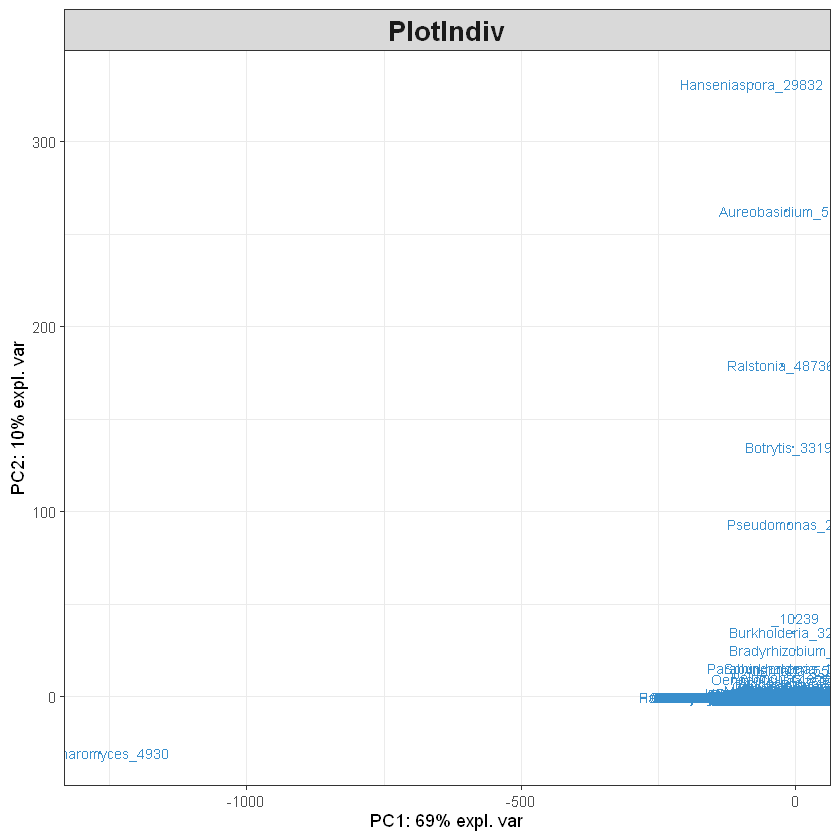

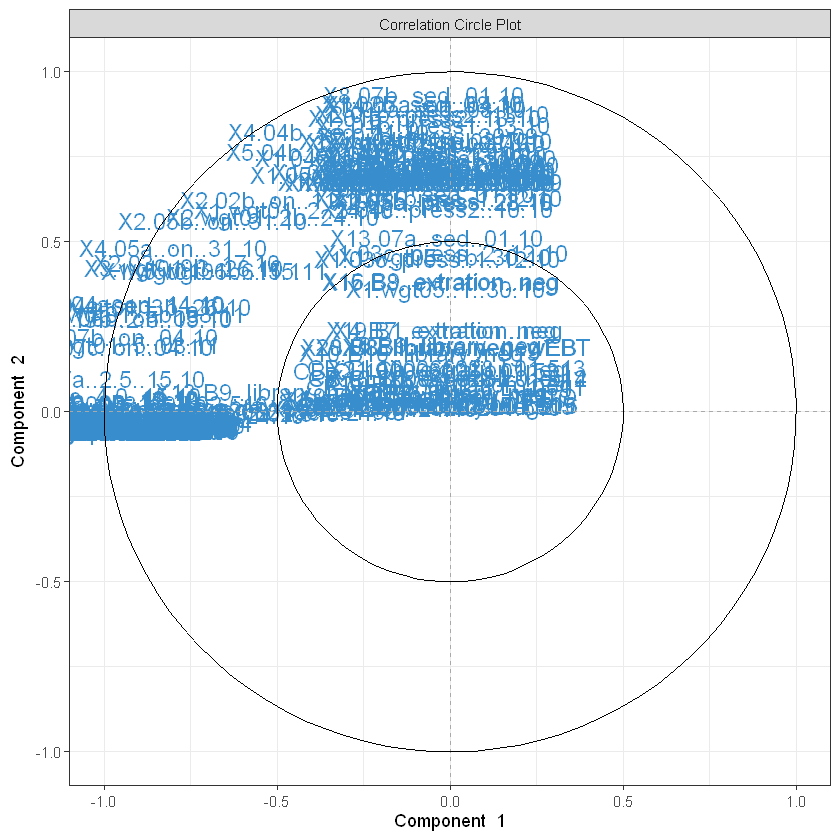

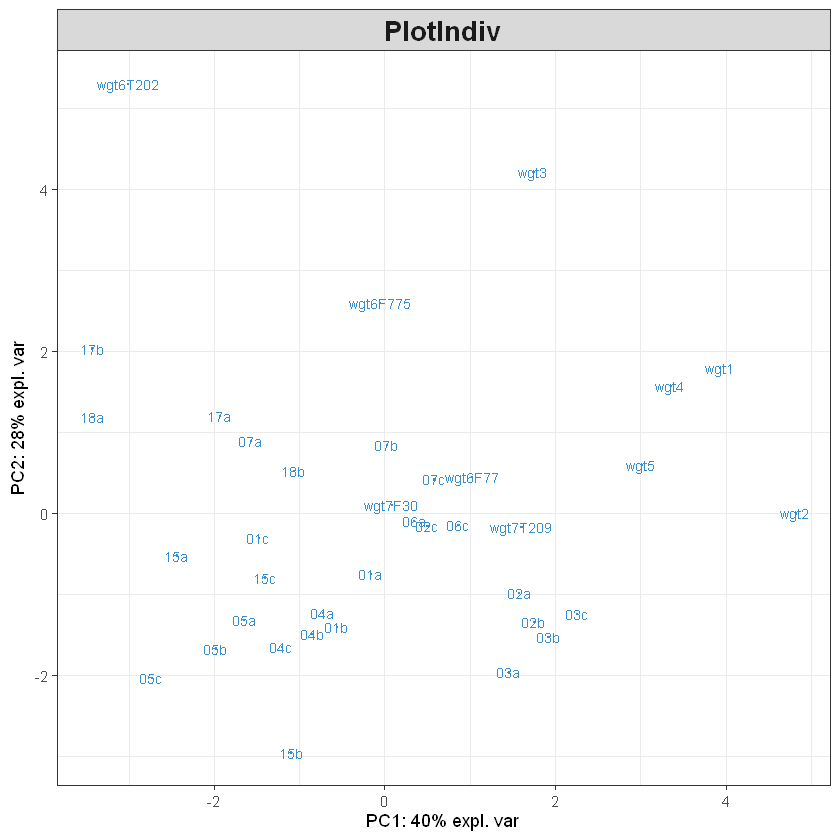

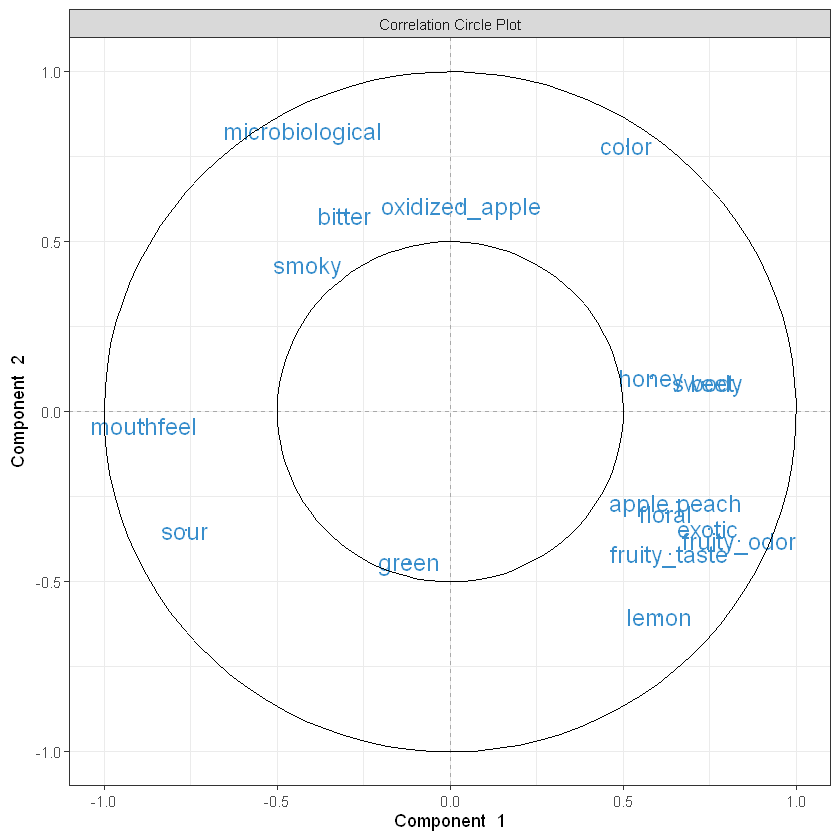

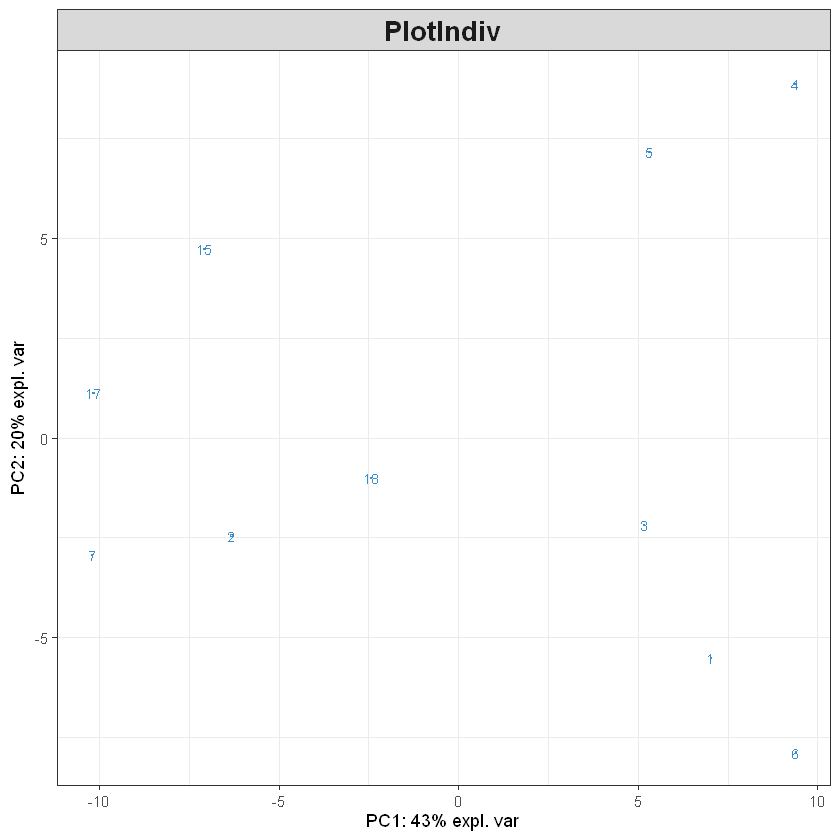

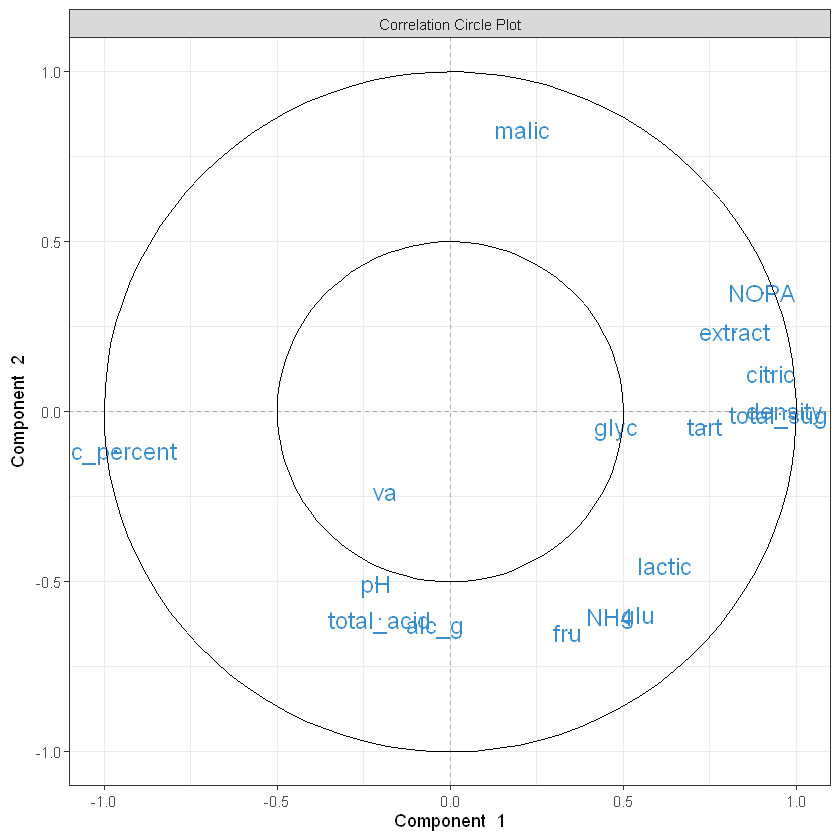

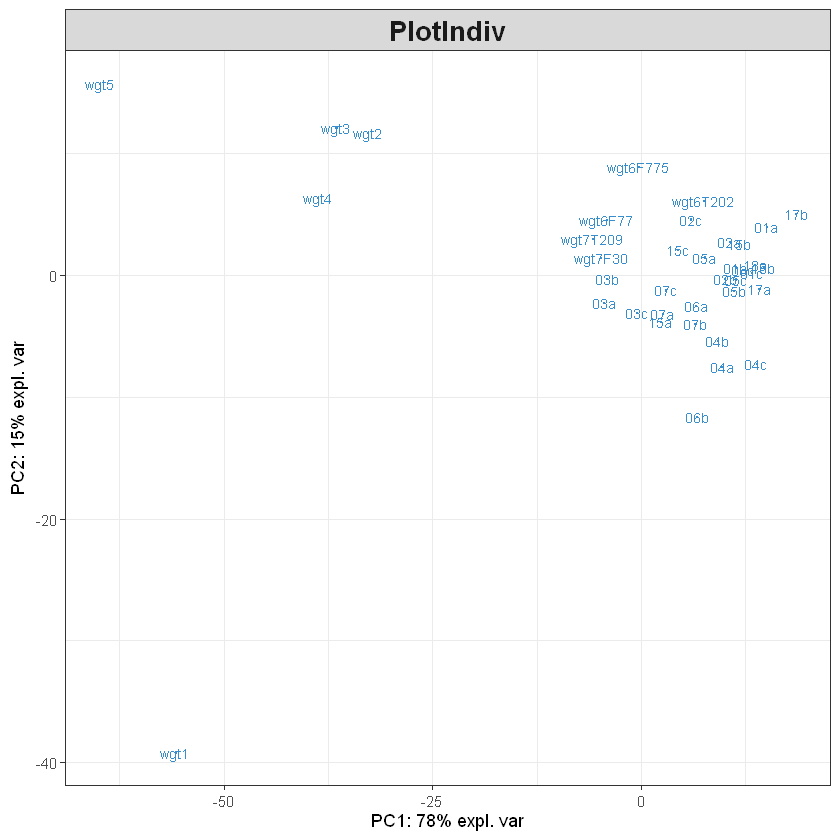

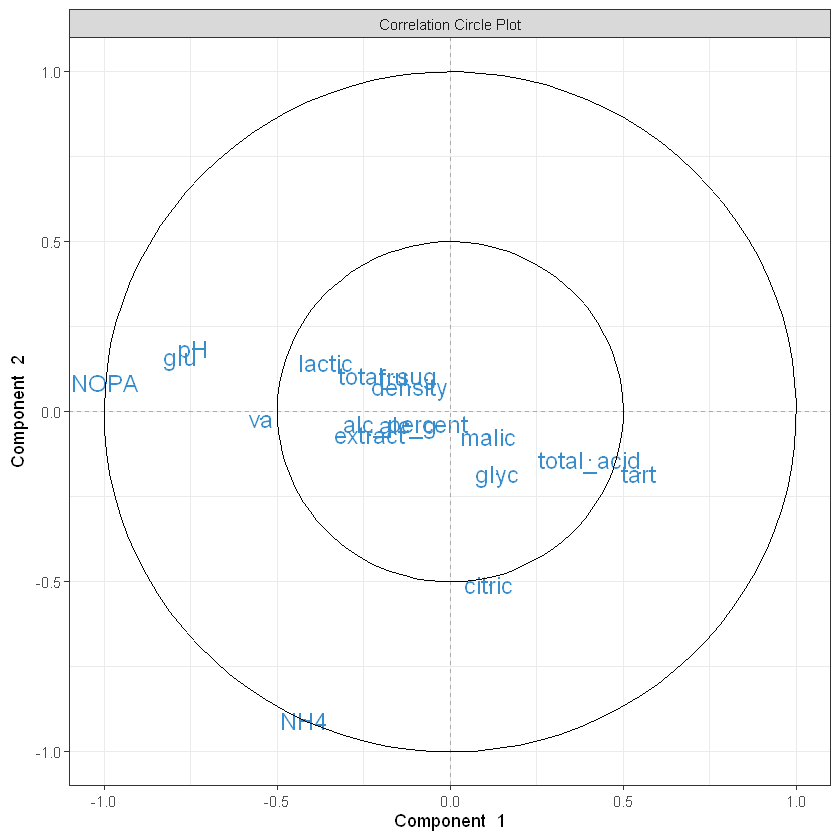

In [19]:
result.pca.multi <- pca(data)   # run the method
plotIndiv(result.pca.multi)  # plot the samples
plotVar(result.pca.multi)    # plot the variables

result.pca.multi <- pca(df_flavour_avgs)   # run the method
plotIndiv(result.pca.multi)  # plot the samples
plotVar(result.pca.multi)    # plot the variables

result.pca.multi <- pca(ferm_start)   # run the method
plotIndiv(result.pca.multi)  # plot the samples
plotVar(result.pca.multi)    # plot the variables

result.pca.multi <- pca(ferm_finish_sep)   # run the method
plotIndiv(result.pca.multi)  # plot the samples
plotVar(result.pca.multi)    # plot the variables

In [20]:
library(mixOmics) # import the mixOmics library
data(breast.TCGA) # extract the TCGA data

X1 <- breast.TCGA$data.train$mirna # use the mirna and mrna expression levels as 
X2 <- breast.TCGA$data.train$mrna  # the X datasets
X <- list(mirna = X1, mrna = X2)

Y <- breast.TCGA$data.train$protein # set the protein levels as the Y dataset

block.pls.result <- block.pls(X, Y, design = "full") # run the method

# plotIndiv(block.pls.result) # plot the samples
# plotVar(block.pls.result, legend = TRUE) # plot the variables

In [21]:
nrow(df_flavour_avgs)
nrow(ferm_start_sep)
nrow(ferm_finish_sep)

[1] 37

[1] 38

[1] 38

In [22]:
# Here we drop 06b because it is not part of some datasets
ferm_start_sep <- ferm_start_sep[row.names(ferm_start_sep) != "06b", , drop = FALSE]
ferm_finish_sep <- ferm_finish_sep[row.names(ferm_finish_sep) != "06b", , drop = FALSE]


In [23]:
nrow(df_flavour_avgs)
nrow(ferm_start_sep)
nrow(ferm_finish_sep)

[1] 37

[1] 37

[1] 37

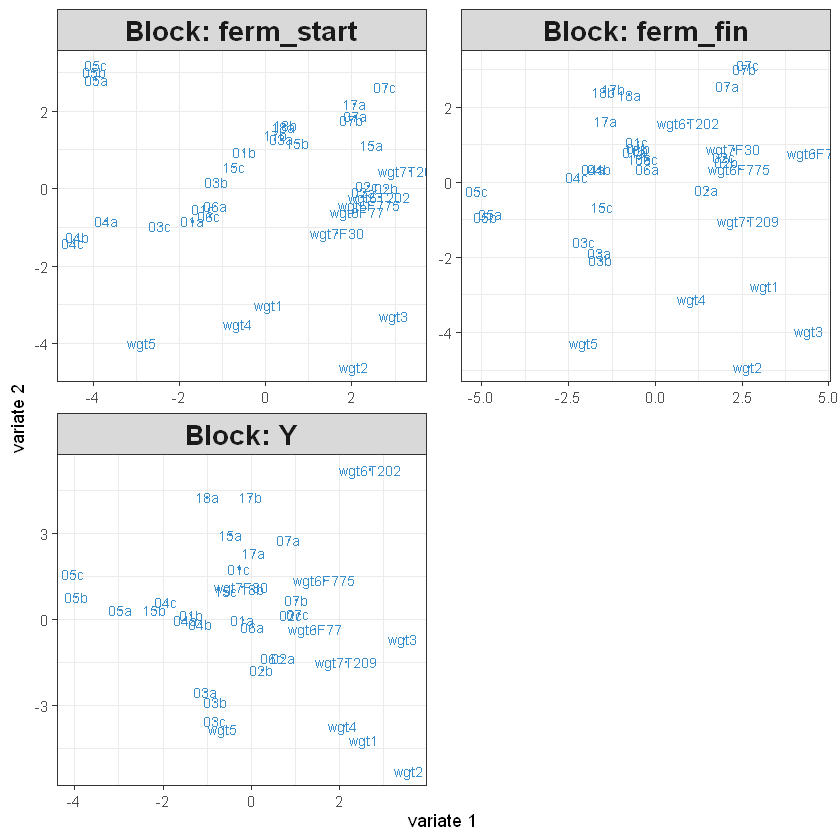

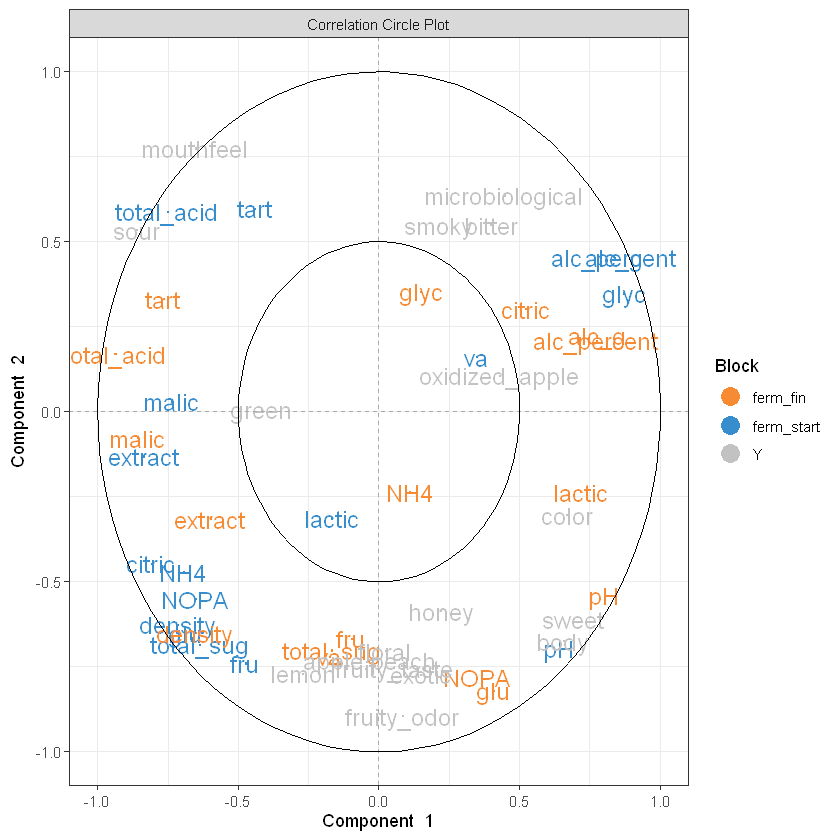

In [24]:
x <- list(ferm_start = ferm_start_sep, ferm_fin = ferm_finish_sep)

block.pls.result.ftir_only <- block.pls(X = x, Y = as.matrix(df_flavour_avgs), design = "full", mode = "regression")

plotIndiv(block.pls.result.ftir_only) # plot the samples
plotVar(block.pls.result.ftir_only, legend = TRUE) # plot the variables

In [25]:
colnames(ferm_finish_sep) <- paste('fin', colnames(ferm_finish_sep), sep = '_')
x_combi <- cbind(ferm_start_sep, ferm_finish_sep)

spls_result_ftir_only <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs))



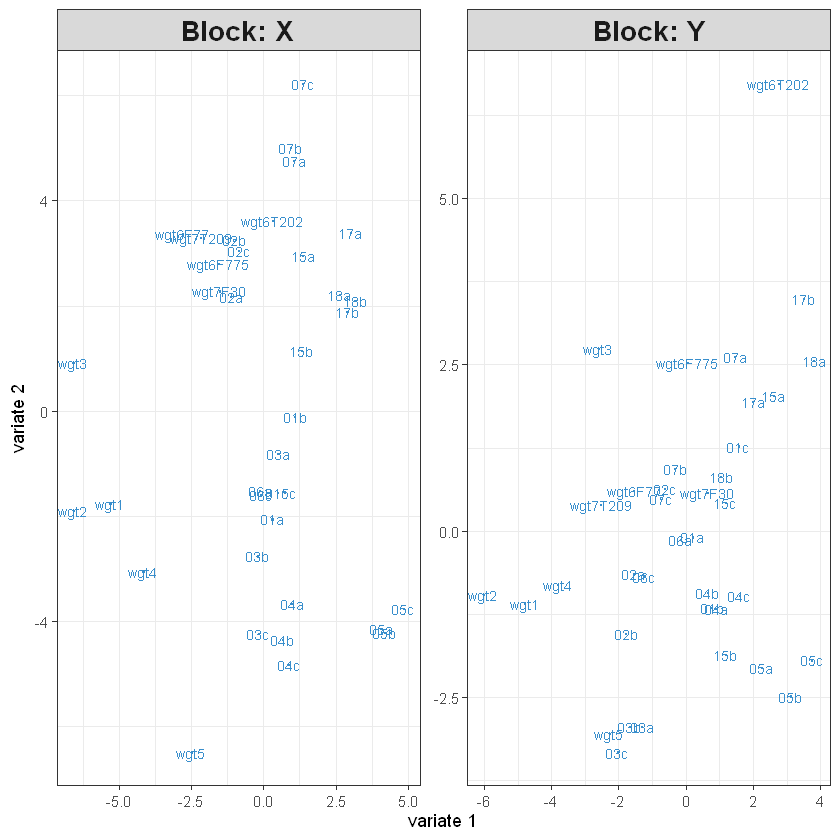

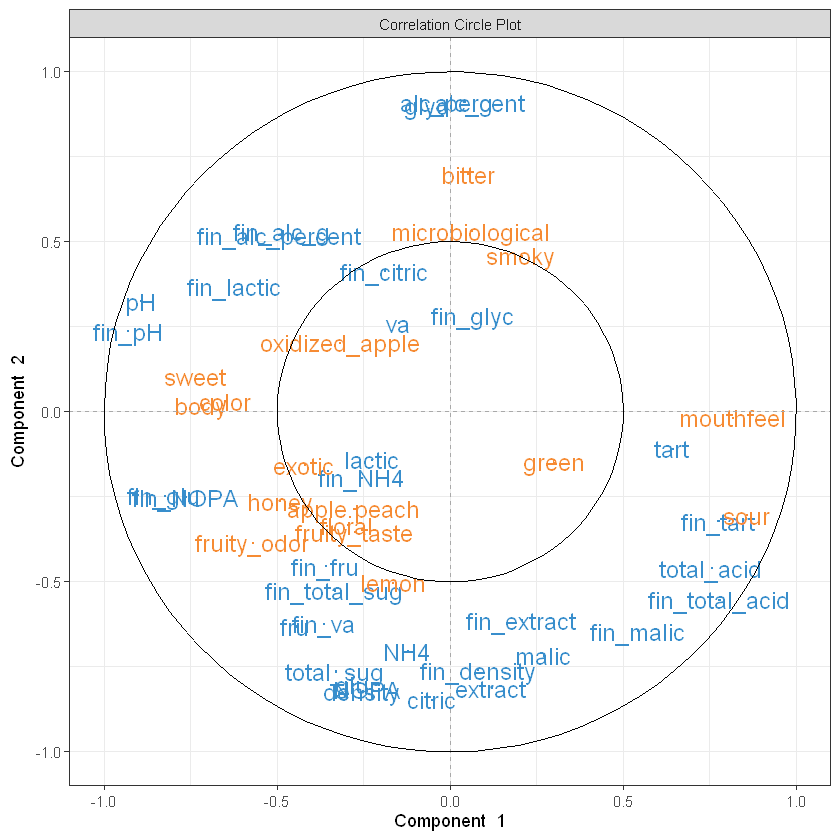

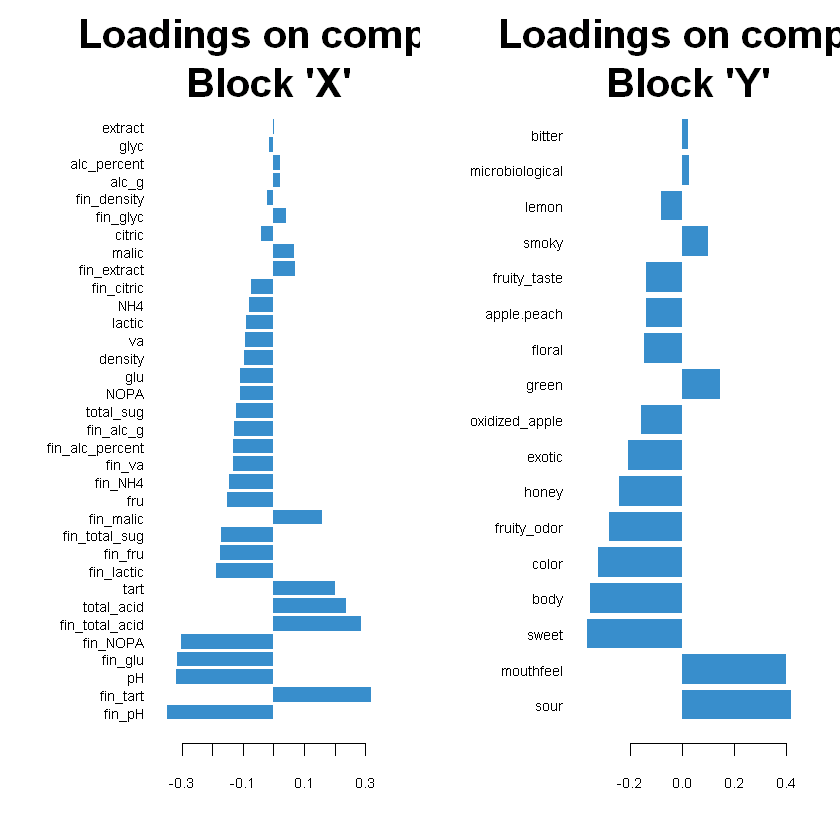

In [26]:
plotIndiv(spls_result_ftir_only)          # Sample plots
plotVar(spls_result_ftir_only)            # Variable plots
plotLoadings(spls_result_ftir_only)       # Loadings to see important features


# Here we try to load and add the minor - major - thiol data

In [27]:
majors <- read.csv("C:/Users/domin/Documents/WUR/Thesis/raw_data/majors16_chrats.csv", row.names = "Compound_mg")
majors <- majors[order(row.names(majors)), ]

minors <- read.csv("C:/Users/domin/Documents/WUR/Thesis/raw_data/minors16_chrats.csv", row.names = "Compound_ug")
minors <- minors[order(row.names(minors)), ]

thiols <- read.csv("C:/Users/domin/Documents/WUR/Thesis/raw_data/thiols16_chrats.csv", row.names = "compound_ng")
thiols <- thiols[order(row.names(thiols)), ]


In [28]:
# We drop WGT3 because of missing data in WGT3
ferm_start_no3 <- ferm_start_sep[row.names(ferm_start_sep) != "wgt3", , drop = FALSE]
ferm_finish_no3 <- ferm_finish_sep[row.names(ferm_finish_sep) != "wgt3", , drop = FALSE]
df_flavour_avgs_no3 <- df_flavour_avgs[row.names(df_flavour_avgs) != "wgt3", , drop = FALSE]

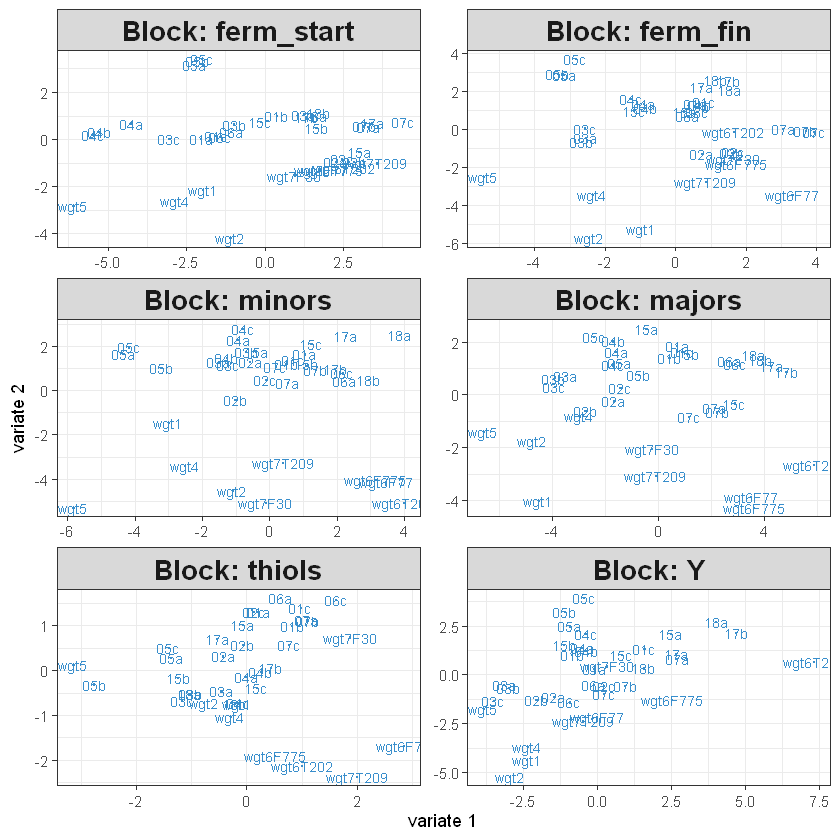

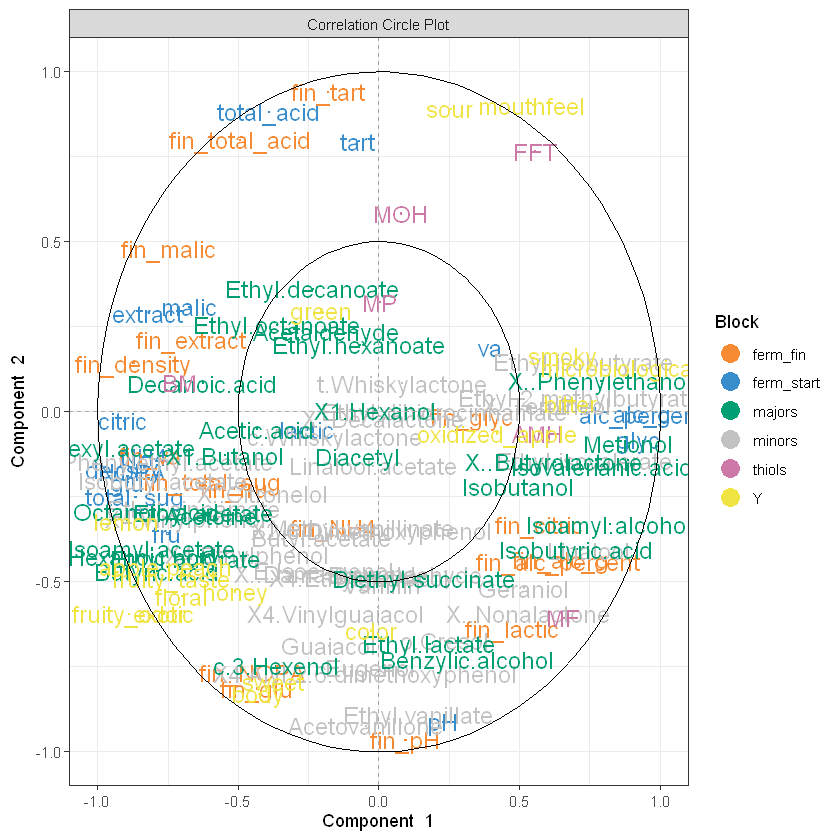

In [29]:
x <- list(ferm_start = ferm_start_no3, ferm_fin = ferm_finish_no3, minors = minors, majors = majors, thiols = thiols)

block.pls.result_ftir_metabolomics <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_no3), design = "full", mode = "regression", near.zero.var = TRUE)

plotIndiv(block.pls.result_ftir_metabolomics) # plot the samples
plotVar(block.pls.result_ftir_metabolomics, legend = TRUE) # plot the variables

In [30]:
colnames(majors) <- paste('maj', colnames(majors), sep = '_')
colnames(minors) <- paste('min', colnames(minors), sep = '_')
colnames(thiols) <- paste('thio', colnames(thiols), sep = '_')

x_combi <- cbind(ferm_start_no3, ferm_finish_no3, minors, majors, thiols)

spls_result_ftir_metabolomics <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs_no3), near.zero.var = TRUE)



Warning message in Check.entry.pls(X, Y, ncomp, keepX, keepY, mode = mode, scale = scale, :
"Zero- or near-zero variance predictors.
 Reset
            predictors matrix to not near-zero variance predictors.

            See $nzv for problematic predictors."


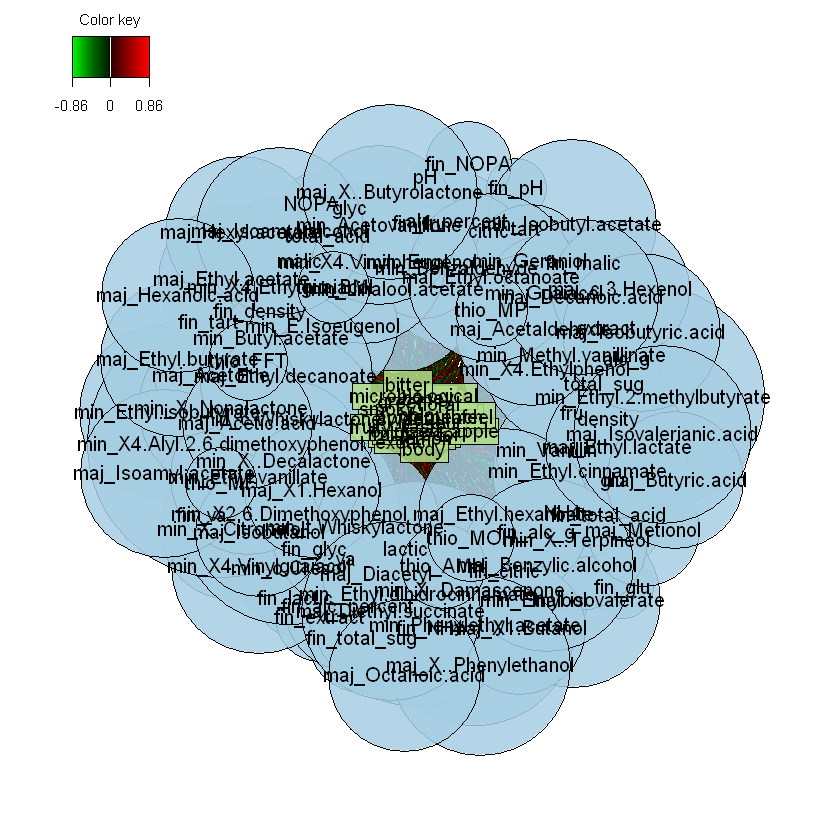

In [31]:
network(spls_result_ftir_metabolomics)

In [32]:
spls_result_ftir_metabolomics$nzv

,freqRatio,percentUnique
,<dbl>,<dbl>
min_X..Ionone,34,8.333333
min_X..Ionone.1,0,2.777778
min_m.Cresol,34,8.333333
min_X4.Propylguaiacol,0,2.777778
min_Siringaldehyde,0,2.777778
maj_Ethyl.propanoate,0,2.777778


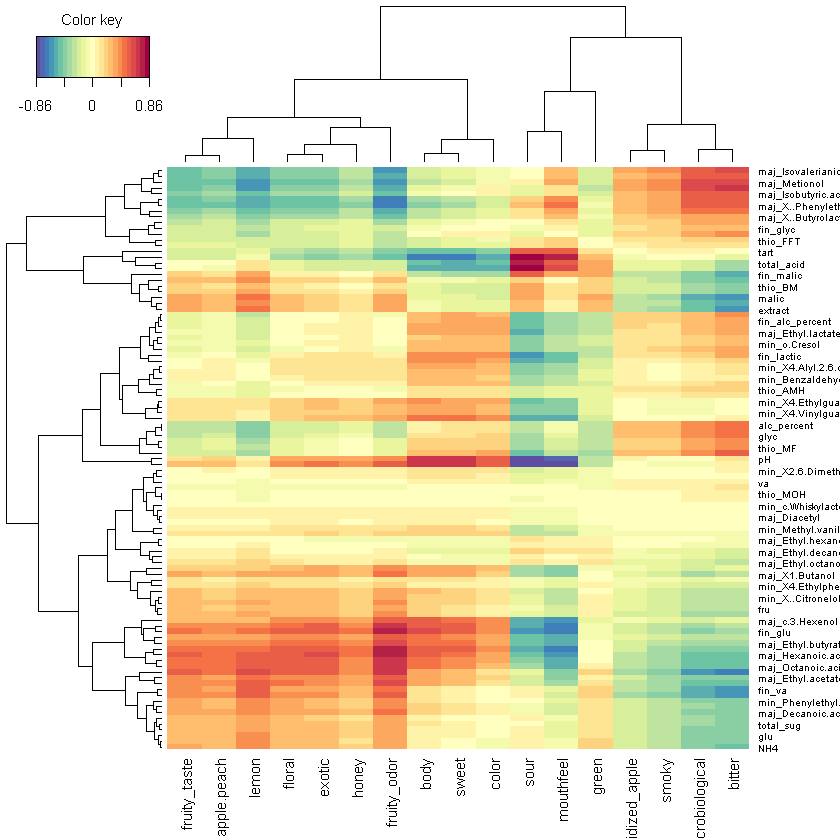

In [33]:
cim(spls_result_ftir_metabolomics)

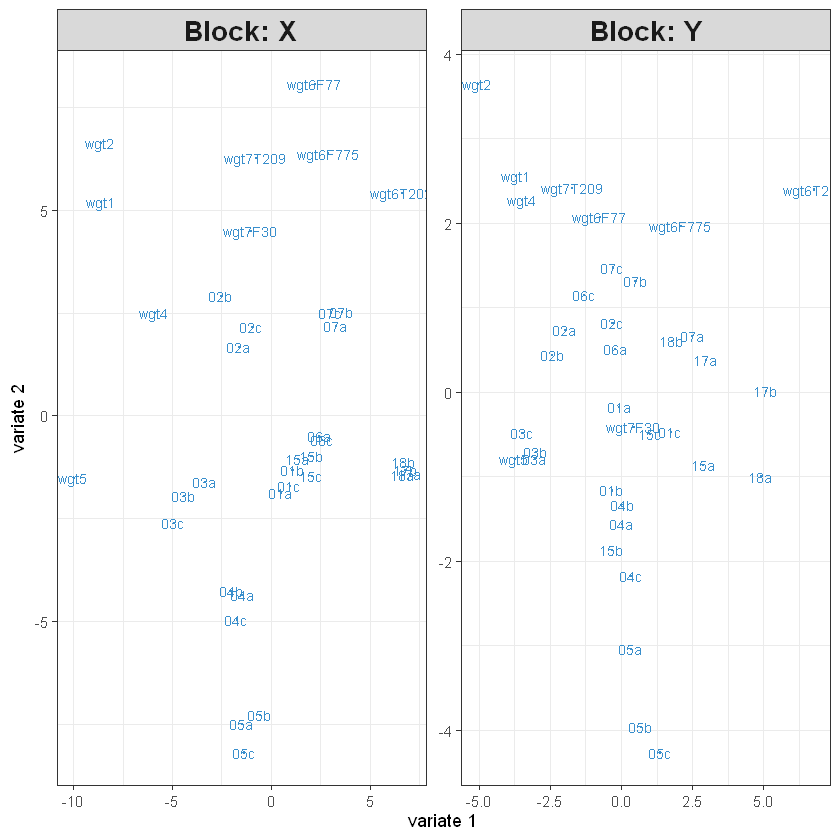

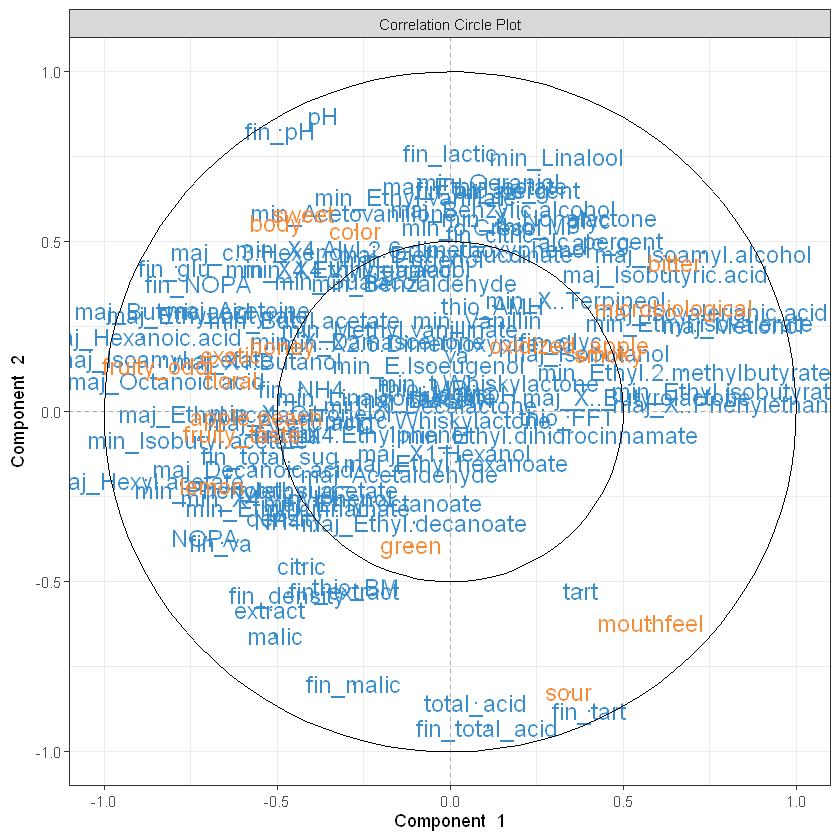

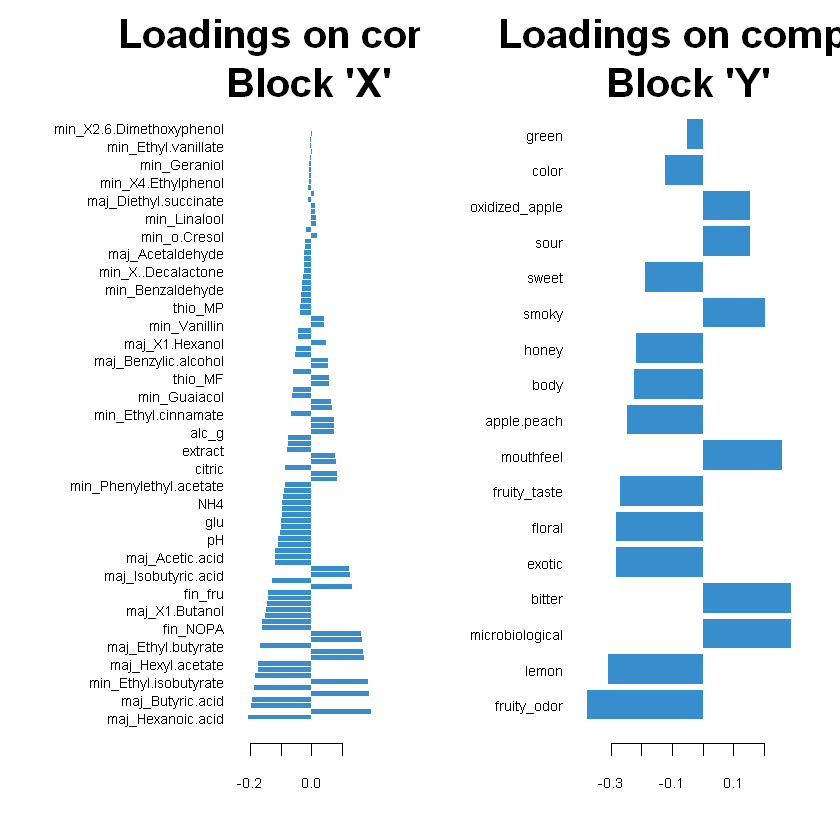

In [34]:
plotIndiv(spls_result_ftir_metabolomics)          # Sample plots
plotVar(spls_result_ftir_metabolomics)            # Variable plots
plotLoadings(spls_result_ftir_metabolomics)       # Loadings to see important features


# Problem

The problem is that it's nigh impossible to get the F77 ect from the names
automatically. This is a shame, because otherwise it is going to have to be done
 manually.


# For the case anyone works on this: Very important

So if you are going to continue working on this, know that in the next block
there is the following lines:

    select(matches("X1.wgt|\\..on..")) 
    select(matches("X1\\.")) 

The thing is: The first of these two, selects THE FIRST VALUE FROM WINERIES and
the ONSET IN STERILE BIOREPLICATES. 

The second one selects ALL OF THE FIRST MEASUREMENTS!

This means the second often takes data from the press! Which is ALSO interesting
 for correlations, as in my file it ended up significantly correlating to some 
press microbes, which were significant in number. When taking onset, there is 
less variety, meaning there is less to correlate with, meaning less significance
 ect.

In [35]:
# ferm_start_meta <- data
ferm_start_meta <- data %>%
#   select(matches("X1.wgt")) 
    select(matches("X1.wgt|\\..on..")) 
    # select(matches("X1\\.")) 


# Alt method of removing first char
# names(data) <- substr(names(data), 2, nchar(names(data)))
colnames(ferm_start_meta) <- sub("^.", "", colnames(ferm_start_meta))

# ferm_timepoints <- lapply(sub("\\..*", "", names(ferm_start_meta)), function(x) as.numeric(x[1]))


colnames(ferm_start_meta) <- sub("^([^\\.]+\\..*?)\\..*", "\\1", colnames(ferm_start_meta))
colnames(ferm_start_meta) <- sub("^\\d.", "", colnames(ferm_start_meta))
colnames(ferm_start_meta) <- substr(colnames(ferm_start_meta), 1, 5)
colnames(ferm_start_meta) <- sub("^\\.", "", colnames(ferm_start_meta))

# ferm_start_meta
# t(ferm_start_meta)

# head(ferm_start_meta)

# length(ferm_timepoints)
fermentation_onset <- aggregate(t(ferm_start_meta), by = list(row.names(t(ferm_start_meta))), FUN = sum)
fermentation_onset <- data.frame(fermentation_onset[,-1], row.names=fermentation_onset[,1])
fermentation_onset <- fermentation_onset[row.names(fermentation_onset) != "06b", , drop = FALSE]


# head(fermentation_onset)

# Here we calculate the sparseness of the fermentation onset data.
In other words, we calculate how many the values are '0' from all columns. 
From here we turn it into a percentage. 

This is also done for counts under 5.

In [36]:
colsum <- nrow(fermentation_onset) * ncol(fermentation_onset)
num_zeroes <- sum(fermentation_onset == 0)
paste0("Percentage of 0: ", (num_zeroes / colsum * 100),"%", sep="")

num_zeroes <- sum(fermentation_onset <= 1)
paste0("Percentage under 1: ", (num_zeroes / colsum * 100),"%", sep="")

num_zeroes <- sum(fermentation_onset <= 2)
paste0("Percentage under 2: ", (num_zeroes / colsum * 100),"%", sep="")

num_zeroes <- sum(fermentation_onset <= 3)
paste0("Percentage under 3: ", (num_zeroes / colsum * 100),"%", sep="")

num_zeroes <- sum(fermentation_onset <= 4)
paste0("Percentage under 4: ", (num_zeroes / colsum * 100),"%", sep="")

num_zeroes <- sum(fermentation_onset <= 5)
paste0("Percentage under 5: ", (num_zeroes / colsum * 100),"%", sep="")



[1] "Percentage of 0: 0%"

[1] "Percentage under 1: 99.9045307687283%"

[1] "Percentage under 2: 99.9381962344925%"

[1] "Percentage under 3: 99.9477431576197%"

[1] "Percentage under 4: 99.9557826718321%"

[1] "Percentage under 5: 99.9603048985765%"

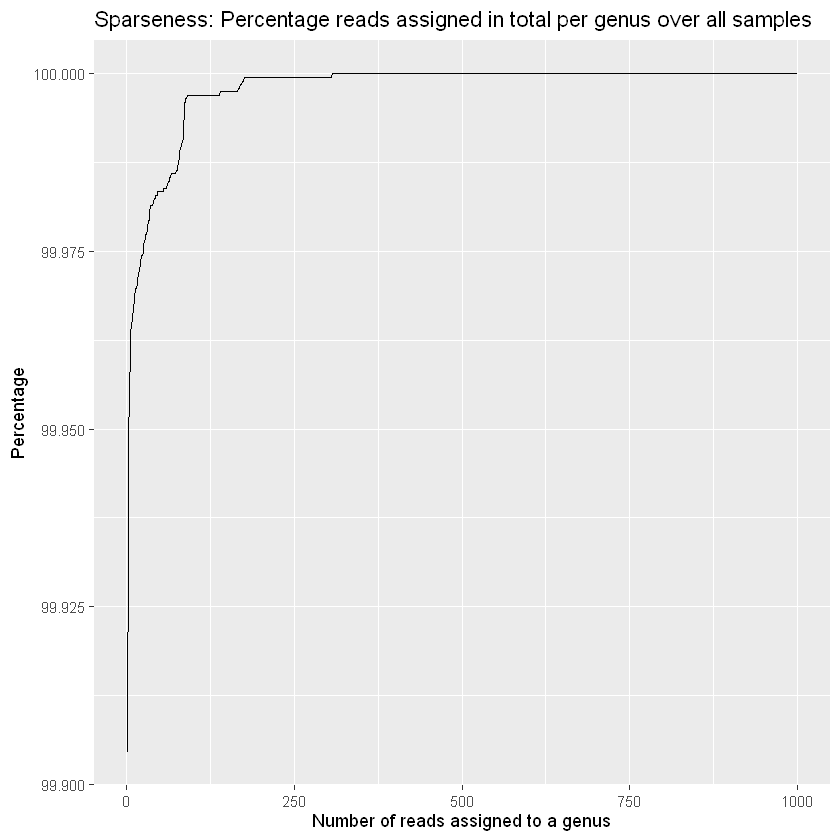

In [37]:
# Calculate percentages
percentages <- data.frame(
    x = 1:1000,
    percentage = sapply(1:1000, function(i) {
        num_zeroes <- sum(fermentation_onset <= i)
        (num_zeroes / colsum * 100)
    })
)

# Create sparseness plot
ggplot(percentages, aes(x = x, y = percentage)) +
    geom_line() +
    labs(
        title = "Sparseness: Percentage reads assigned in total per genus over all samples",
        x = "Number of reads assigned to a genus",
        y = "Percentage"
    )

In [38]:
# Here we make the rownames the same as created previously
rownames(fermentation_onset) <- gsub("wgt0", "wgt", rownames(fermentation_onset))

# And here we filter all the sets
ferm_start_red <- ferm_start_no3[row.names(ferm_start_no3) %in% row.names(fermentation_onset), ]
ferm_finish_red <- ferm_finish_no3[row.names(ferm_finish_no3) %in% row.names(fermentation_onset), ]
df_flavour_avgs_red <- df_flavour_avgs_no3[row.names(df_flavour_avgs_no3) %in% row.names(fermentation_onset), ]
minors_red <- minors[row.names(minors) %in% row.names(fermentation_onset), ]
majors_red <- majors[row.names(majors) %in% row.names(fermentation_onset), ]
thiols_red <- thiols[row.names(thiols) %in% row.names(fermentation_onset), ]
fermentation_onset_red <- fermentation_onset[row.names(fermentation_onset) %in% row.names(df_flavour_avgs_red), ]

head(fermentation_onset)

,Saccharomyces_4930,Hanseniaspora_29832,Ralstonia_48736,Aureobasidium_5579,Pseudomonas_286,Burkholderia_32008,Paraburkholderia_1822464,Bradyrhizobium_374,Acidocella_50709,Botrytis_33196,⋯,Valsaria_338773,Neidium_432550,Zosterodasys_502091,Cyclotrichium_696132,Dictyococcus_889454,Nelsenium_1340027,Clitocella_1522124,Myrmicinosporidium_2820144,Hygrocybe_51006,Dermonema_997601
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,85.138867,10.748822,1.533768,1.2731874,0.02678742,0.2117357,0.13023309,0.09263048,0.09486956,0.30012357,⋯,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387
01b,85.759702,2.717695,1.875903,1.4919158,0.54629115,0.2509660,0.15192904,0.09701982,0.07753114,0.37022006,⋯,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792
01c,85.155760,10.650295,1.165258,1.2869003,0.21035169,0.1775670,0.09719915,0.33892903,0.07648360,0.28353843,⋯,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948
02a,5.632199,85.433537,5.941122,0.1926942,0.38023345,0.7472209,0.49511967,0.36282085,0.25608101,0.05210135,⋯,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805
02b,38.549172,75.688631,11.898185,0.6268448,0.87373691,1.5995364,1.02918863,0.88800412,0.66556569,0.18587310,⋯,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938
02c,15.225245,83.039183,14.487851,0.4946286,0.70034107,1.7744490,1.16936945,0.86878777,0.63510541,0.12930302,⋯,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475


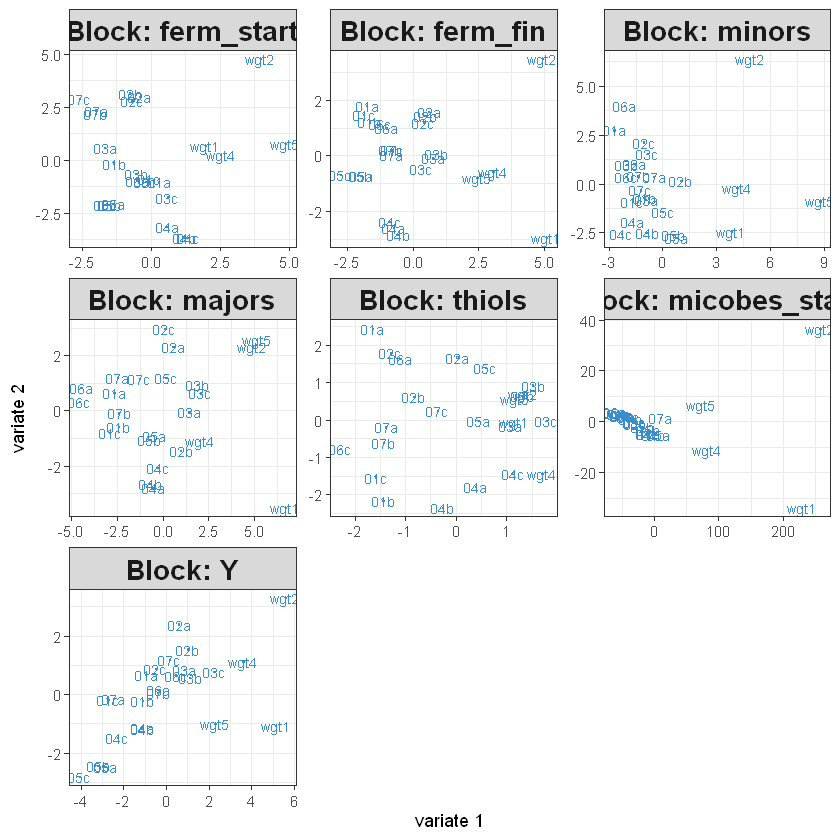

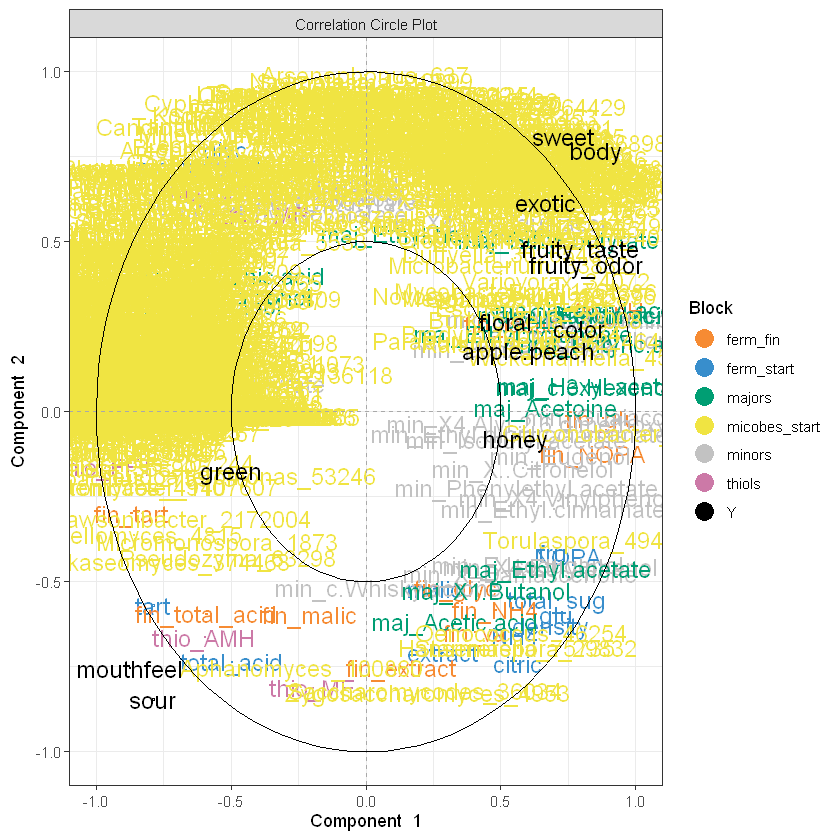

In [39]:
x <- list(ferm_start = ferm_start_red, ferm_fin = ferm_finish_red, 
            minors = minors_red, majors = majors_red, 
            thiols = thiols_red, micobes_start = fermentation_onset_red)




block.pls.result_ftir_metabolome_metagenomic_start <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "regression", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "canonical", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "invariant", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "classic", near.zero.var = TRUE)

plotIndiv(block.pls.result_ftir_metabolome_metagenomic_start) # plot the samples
plotVar(block.pls.result_ftir_metabolome_metagenomic_start, legend = TRUE, cutoff = 0.5) # plot the variables

In [40]:
x_combi <- cbind(ferm_start = ferm_start_red, ferm_fin = ferm_finish_red, 
            minors = minors_red, majors = majors_red, 
            thiols = thiols_red, micobes_start = fermentation_onset_red)

# spls_result <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs_red), near.zero.var = TRUE, scale = TRUE)
# spls_result <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs_red), scale = TRUE, mode = "regression")
spls_result_ftir_metabol_metagen_start <- spls(X = fermentation_onset_red, Y = as.matrix(df_flavour_avgs_red), scale = TRUE, mode = "regression")



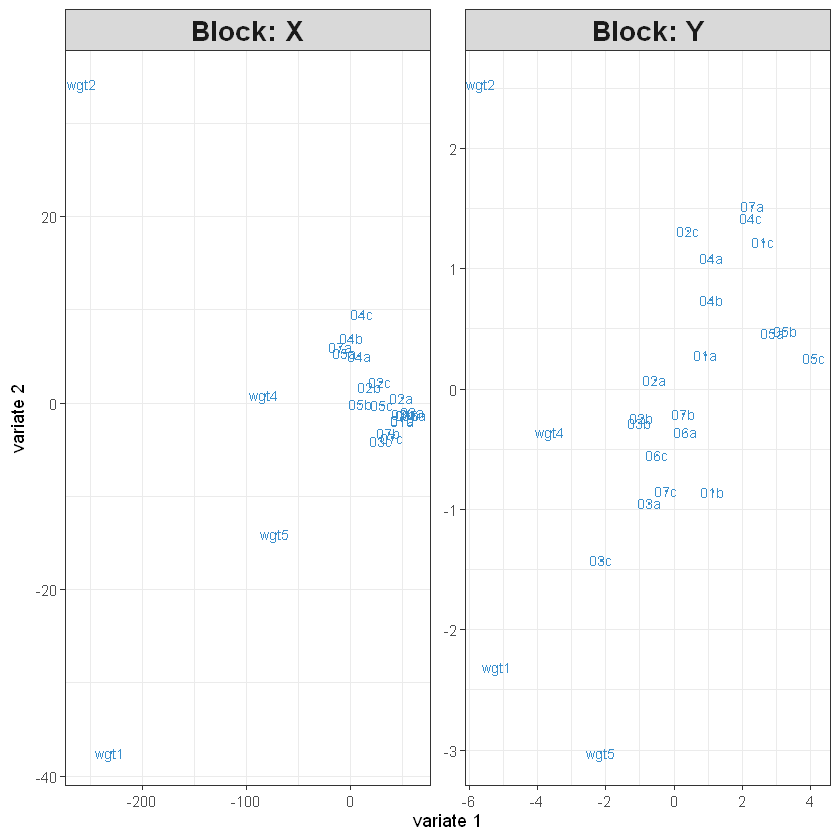

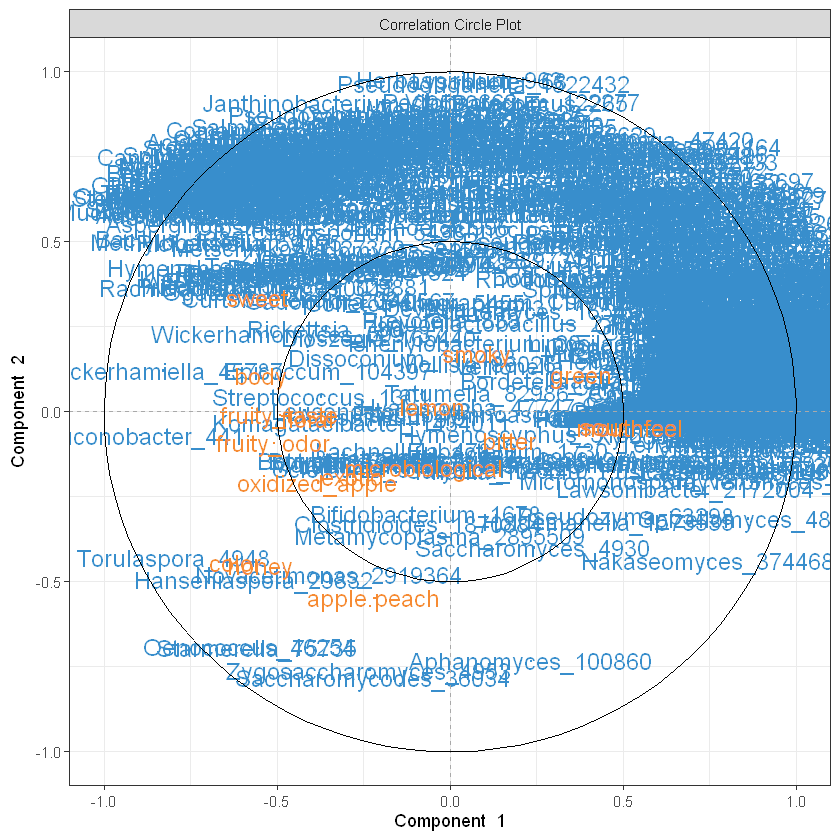

In [41]:
plotIndiv(spls_result_ftir_metabol_metagen_start)          # Sample plots
plotVar(spls_result_ftir_metabol_metagen_start)            # Variable plots
# plotLoadings(spls_result)       # Loadings to see important features


In [42]:
# network(spls_result)
spls_result_ftir_metabol_metagen_start


Call:
 spls(X = fermentation_onset_red, Y = as.matrix(df_flavour_avgs_red), mode = "regression", scale = TRUE) 

 sPLS with a 'regression' mode with 2 sPLS components. 
 You entered data X of dimensions: 24 7371 
 You entered data Y of dimensions: 24 17 

 Selection of [7371] [7371] variables on each of the sPLS components on the X data set. 
 Selection of [17] [17] variables on each of the sPLS components on the Y data set. 

 Main numerical outputs: 
 -------------------- 
 loading vectors: see object$loadings 
 variates: see object$variates 
 variable names: see object$names 

 Functions to visualise samples: 
 -------------------- 
 plotIndiv, plotArrow 

 Functions to visualise variables: 
 -------------------- 
 plotVar, plotLoadings, network, cim 

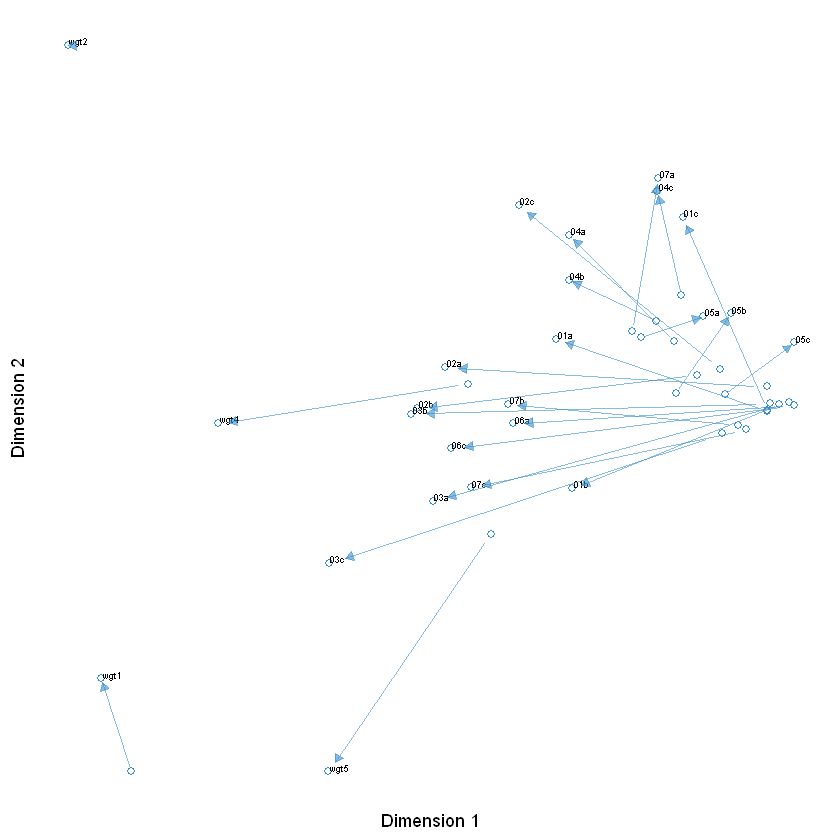

In [43]:
plotArrow(spls_result_ftir_metabol_metagen_start)
# sort(spls_result$loadings)

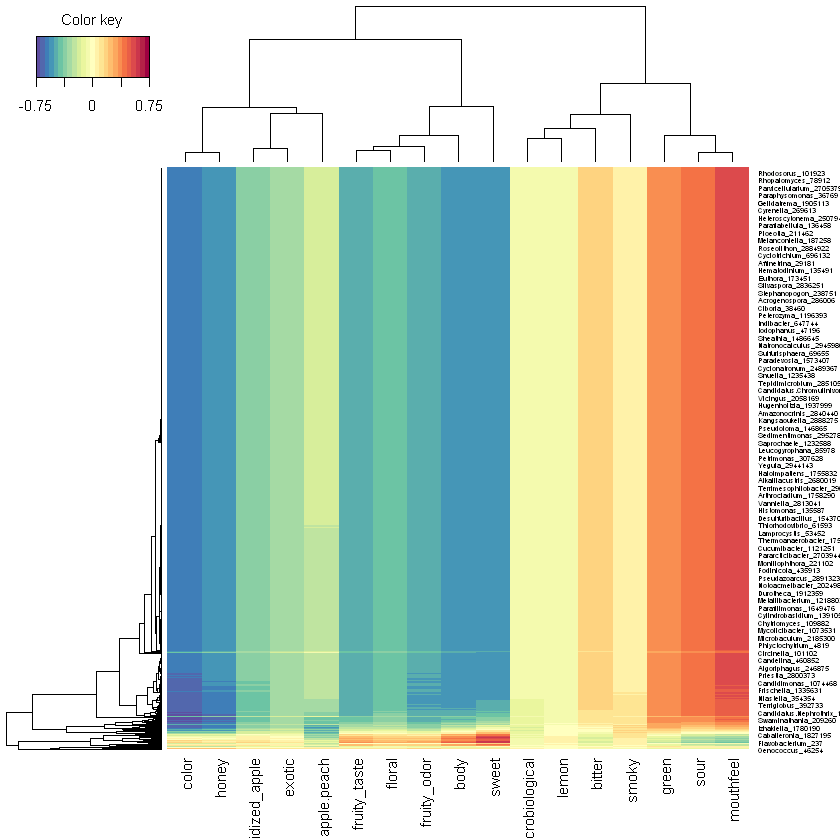

In [44]:
cim(spls_result_ftir_metabol_metagen_start)

In [45]:
row.names(fermentation_onset)

[1] "01a"  "01b"  "01c"  "02a"  "02b"  "02c"  "03a"  "03b"  "03c"  "04a" 
[11] "04b"  "04c"  "05a"  "05b"  "05c"  "06a"  "06c"  "07a"  "07b"  "07c" 
[21] "wgt1" "wgt2" "wgt3" "wgt4" "wgt5" "wgt6" "wgt7"

In [46]:
row.names(ferm_start_sep)

[1] "01a"      "01b"      "01c"      "02a"      "02b"      "02c"     
 [7] "03a"      "03b"      "03c"      "04a"      "04b"      "04c"     
[13] "05a"      "05b"      "05c"      "06a"      "06c"      "07a"     
[19] "07b"      "07c"      "15a"      "15b"      "15c"      "17a"     
[25] "17b"      "18a"      "18b"      "wgt1"     "wgt2"     "wgt3"    
[31] "wgt4"     "wgt5"     "wgt6F77"  "wgt6F775" "wgt6T202" "wgt7F30" 
[37] "wgt7T209"

# Here we finally include the final metagenomics data

The method we do it is by using the first numbers before the first . per sample
and we take the highest to get the final. 

In [47]:
microbes_finish <- data

colnames(microbes_finish) <- sub("^.", "", colnames(microbes_finish))


# microbes_finish <- lapply(sub("\\..*", "", names(microbes_finish)), function(x) as.numeric(x[1]))


colnames(microbes_finish) <- sub("^([^\\.]+\\..*?)\\..*", "\\1", colnames(microbes_finish))
# colnames(microbes_finish) <- sub("^\\d.", "", colnames(microbes_finish))
# colnames(microbes_finish) <- substr(colnames(microbes_finish), 1, 5)
# colnames(microbes_finish) <- sub("^\\.", "", colnames(microbes_finish))

# # microbes_finish
# t(microbes_finish)

# names(microbes_finish)
# unique(sapply(names(microbes_finish), function(x) strsplit(x, "\\.")[[1]][2]))

# microbes_finish
unique_values <- unique(sapply(names(microbes_finish), function(x) strsplit(x, "\\.")[[1]][2]))

last_values <- vector()

for (value in unique_values) {
    matching_cols <- grep(paste0("\\.", value, "$"), names(microbes_finish), value = TRUE)
    number <- (max(as.numeric(sapply(matching_cols, function(x) strsplit(x, "\\.")[[1]][1]))))
    last_values <- append(last_values, paste0(number, ".", value))
}
# append(last_values, paste0(number, ".", value))
# last_values
# names(microbes_finish)
intersecting <- intersect(last_values, names(microbes_finish))
# microbes_finish <- microbes_finish[, last_values]
# microbes_finish
# intersecting
microbes_finish <- microbes_finish[, intersecting]

colnames(microbes_finish) <- sub("^\\d.", "", colnames(microbes_finish))
colnames(microbes_finish) <- sub("^\\.", "", colnames(microbes_finish))

names(microbes_finish) <- sub("wgt0", "wgt", names(microbes_finish))

microbes_finish <- microbes_finish %>% select(sort(names(.)))

head(microbes_finish)
microbes_finish <- t(microbes_finish)

Warning message:
"NAs introduced by coercion"
Warning message:
"NAs introduced by coercion"


,01a,01b,01c,02a,02b,02c,03a,03b,03c,04a,⋯,wgt1,wgt2,wgt3,wgt3b,wgt4,wgt5,wgt6,wgt6press209,wgt6press209b,wgt7
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Saccharomyces_4930,85.8000563,85.828769847,85.8143363,61.4826631,16.41610247,34.07895004,83.22628632,82.00602568,85.786514332,85.1376849,⋯,50.45921077,85.82800082,85.8057659,16.571084529,85.7094045,85.3784300,85.78734429,1.97597503,1.95307057,85.83259829
Hanseniaspora_29832,2.4594727,1.058216989,1.4694500,0.6874543,0.05751046,0.18936208,0.89138871,0.55684719,0.889481924,0.2407346,⋯,53.51115864,0.22607812,2.0603325,3.295682011,2.7043367,0.6421915,2.67187177,85.81746635,85.81624765,0.72281965
Ralstonia_48736,0.7893883,0.932611193,1.3290840,2.4841142,0.96835413,0.93650476,3.70400891,2.07874105,1.273904871,0.7660627,⋯,4.44377277,0.57192467,0.9464107,0.629866790,3.4180206,8.5932398,0.20247280,0.18581972,0.27116659,0.27030190
Aureobasidium_5579,0.2470775,0.128564140,0.1618801,0.4166916,0.09731958,0.07487114,0.01861843,0.01078252,0.001727654,0.1757970,⋯,0.04852563,1.05659684,0.1804208,0.003890477,0.7868174,0.2043049,0.95848645,0.53342386,0.62539850,0.68855220
Pseudomonas_286,0.0184872,0.002667623,0.2237202,0.4986049,0.18144543,0.21577915,0.72923969,0.63270837,0.364794527,0.1927628,⋯,0.43328558,0.64532471,0.8126623,0.100910340,0.7954380,0.2091250,0.60663859,0.16300913,0.38819487,0.43660660
Burkholderia_32008,0.2098168,0.227912725,0.3091260,0.8845175,0.32988950,0.22344800,0.81388169,0.45363568,0.282186934,0.1751921,⋯,0.70813670,0.09591575,0.1729639,0.102219413,0.5652776,1.3877061,0.04299654,0.02770139,0.04407882,0.05493686


In [48]:
fermentation_final_red <- microbes_finish[row.names(microbes_finish) %in% row.names(df_flavour_avgs_red), ]
row.names(fermentation_final_red)

[1] "01a"  "01b"  "01c"  "02a"  "02b"  "02c"  "03a"  "03b"  "03c"  "04a" 
[11] "04b"  "04c"  "05a"  "05b"  "05c"  "06a"  "06c"  "07a"  "07b"  "07c" 
[21] "wgt1" "wgt2" "wgt4" "wgt5"

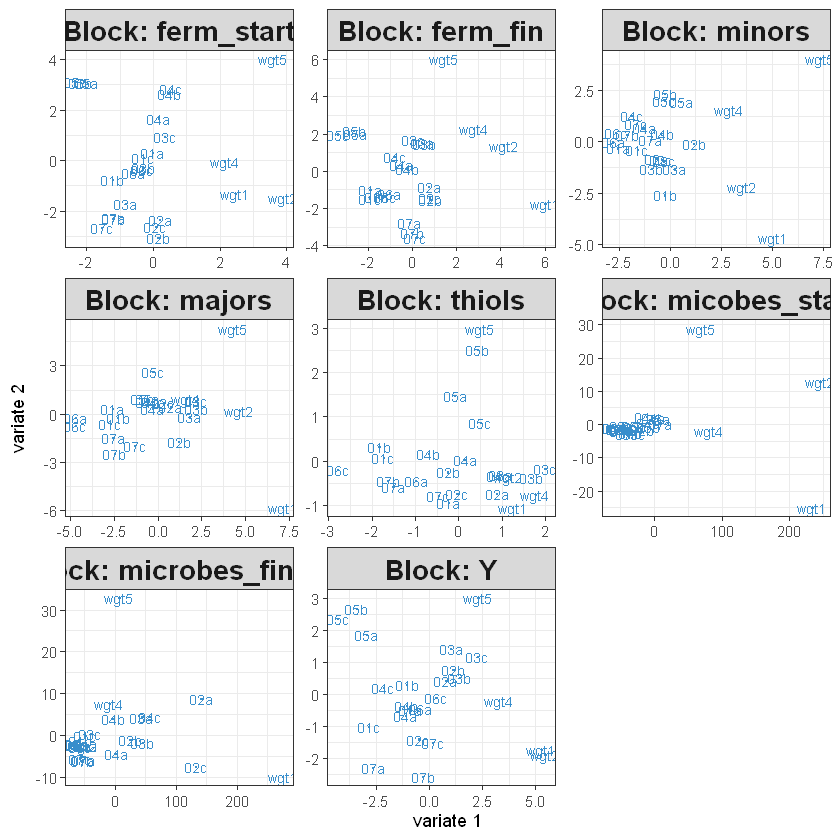

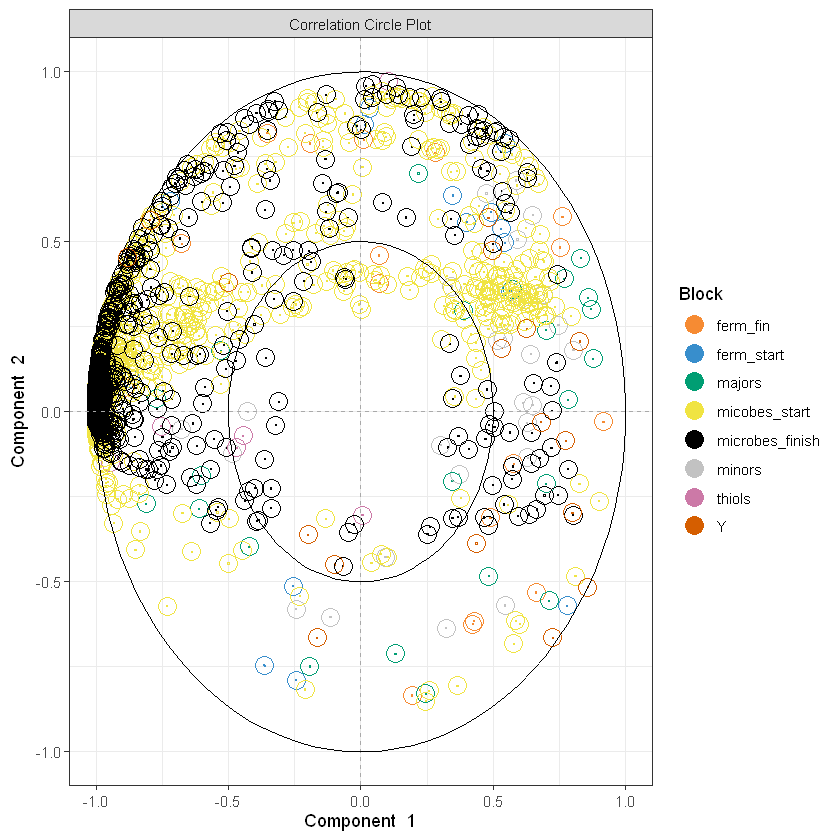

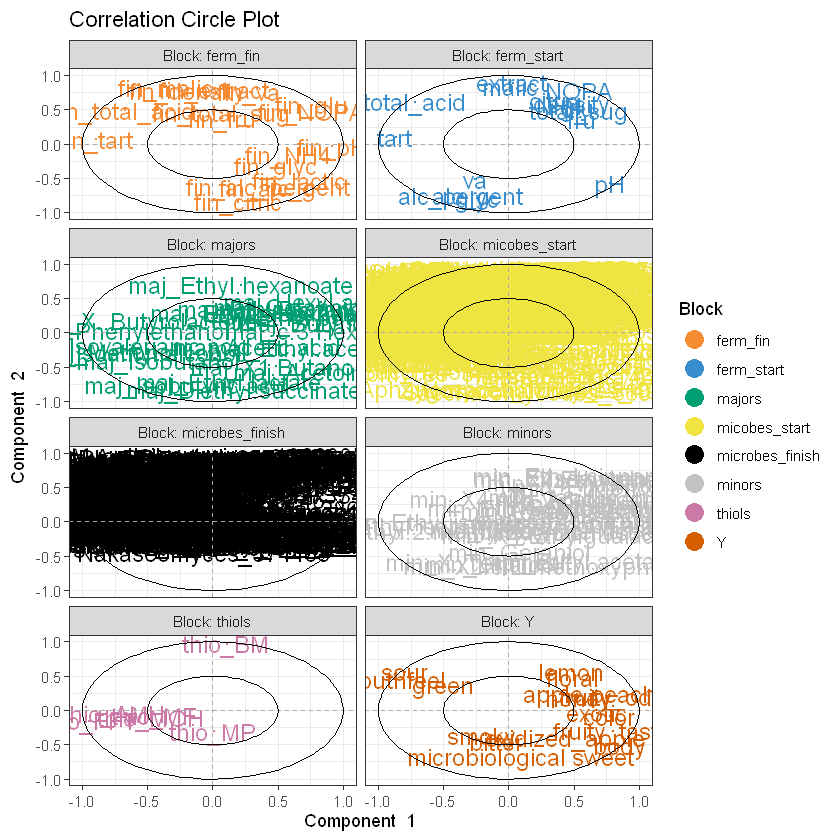

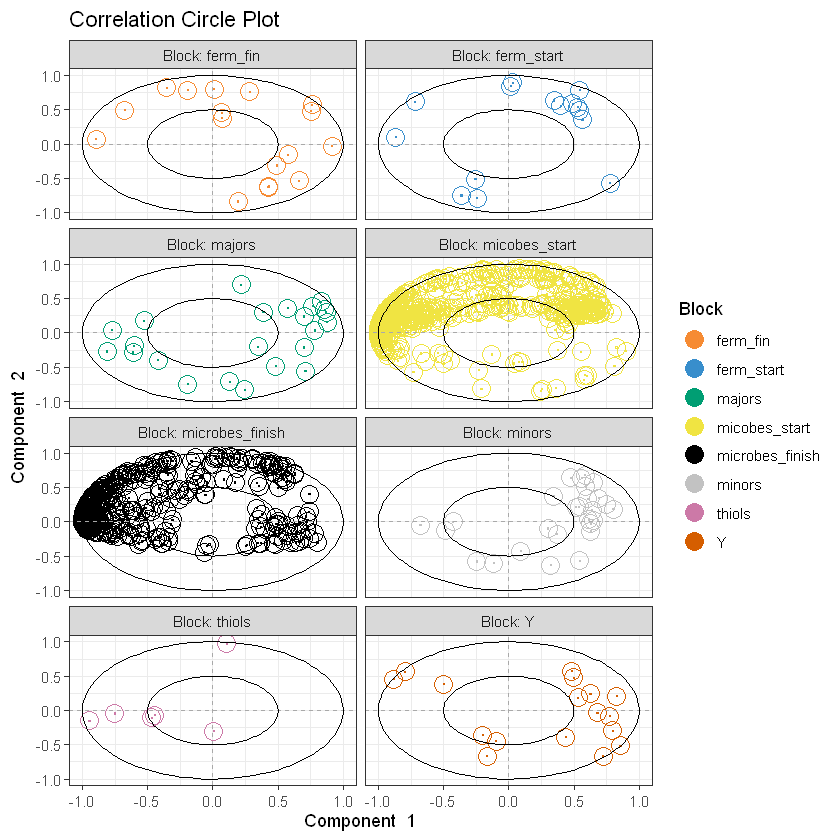

In [49]:
x <- list(ferm_start = ferm_start_red, ferm_fin = ferm_finish_red, 
            minors = minors_red, majors = majors_red, 
            thiols = thiols_red, micobes_start = fermentation_onset_red,
            microbes_finish = fermentation_final_red)




block.pls.result_all_data <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "regression", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "canonical", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "invariant", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "classic", near.zero.var = TRUE)

plotIndiv(block.pls.result_all_data) # plot the samples
plotVar(block.pls.result_all_data, legend = TRUE, cutoff = 0.3, var.names = FALSE) # plot the variables
plotVar(block.pls.result_all_data, legend = TRUE, cutoff = 0.3, overlap = FALSE) # plot the variables
plotVar(block.pls.result_all_data, legend = TRUE, cutoff = 0.3, overlap = FALSE, var.names = FALSE) # plot the variables

# Here we try to calculate the euclidian distances

We can calculate euclidian distances based on the PCA to see which points are 
the closest. The closer points can be manually identified and checked.

In [50]:
# Using the plot = false option, we get all the raw results
df <- plotVar(block.pls.result_all_data, legend = TRUE, cutoff = 0, plot=FALSE)
df_y <- df[df$Block == "Y", ]
df_non_y <- df[df$Block != "Y", ]



In [51]:
# Create matrices of coordinates
coords_y <- as.matrix(df_y[, c("x", "y")])
coords_non_y <- as.matrix(df_non_y[, c("x", "y")])




In [52]:
# Proxy package dist works great for easily calculating euclid. distances
euclidian_distance <- dist(coords_y, coords_non_y, method="euclidean", convert_similarities = TRUE)


In [53]:
euclidian_distance

                    density       alc_g   total_sug         glu         fru
color           0.728927408 1.315610594 0.625633191 0.669540095 0.486714392
fruity_odor     0.506531477 1.524970764 0.404682636 0.445016612 0.300579358
lemon           0.018268445 1.564584349 0.096963855 0.057689034 0.232134784
apple.peach     0.368389078 1.399742893 0.265766197 0.309674449 0.126346201
exotic          0.645884545 1.265325374 0.544874920 0.588625534 0.402120952
oxidized_apple  0.975370312 0.877291609 0.890251040 0.929691246 0.752317438
                 total_acid          pH          va        tart      lactic
color           1.648312464 0.484988224 1.115212977 1.652901121 0.730147904
fruity_odor     1.597567791 0.778873591 1.300433227 1.699017643 0.883396678
lemon           1.199938807 1.179345156 1.311188123 1.430744545 0.904069155
apple.peach     1.394432574 0.828339490 1.162423032 1.502058882 0.738511664
exotic          1.540502109 0.548243970 1.053074723 1.554421400 0.652806340
oxidized_app

In [54]:
# write.table(t(euclidian_distance), sep = "\t", file = "euclidian_distances_xy.tsv")
# # In Excel, we can manually change the .1 values to _final values

Warning message in Check.entry.pls(X, Y, ncomp, keepX, keepY, mode = mode, scale = scale, :
"Zero- or near-zero variance predictors.
 Reset
            predictors matrix to not near-zero variance predictors.

            See $nzv for problematic predictors."


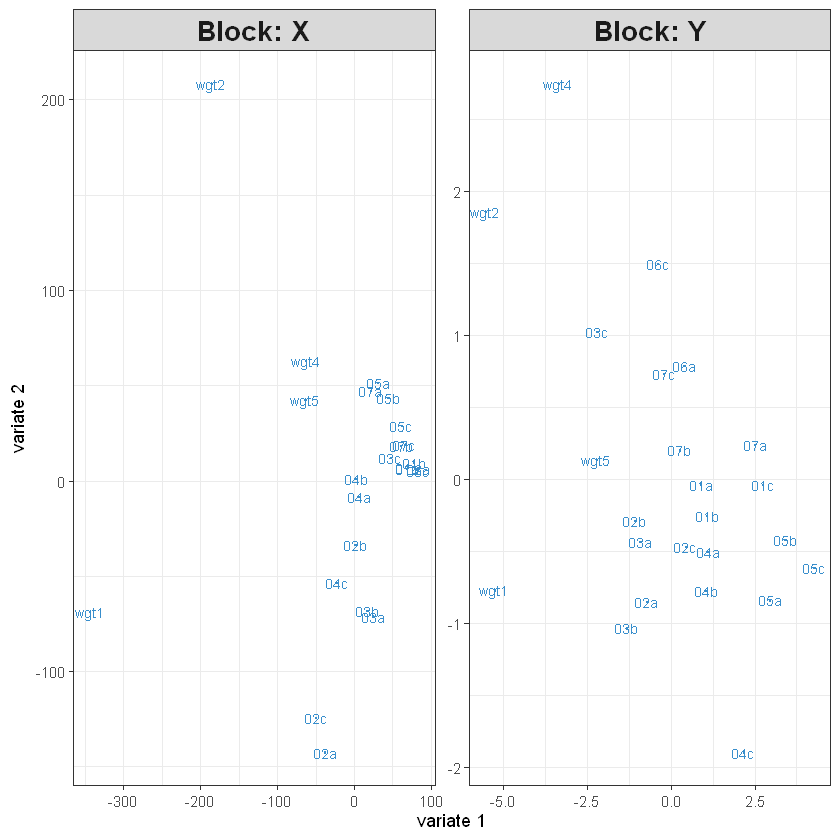

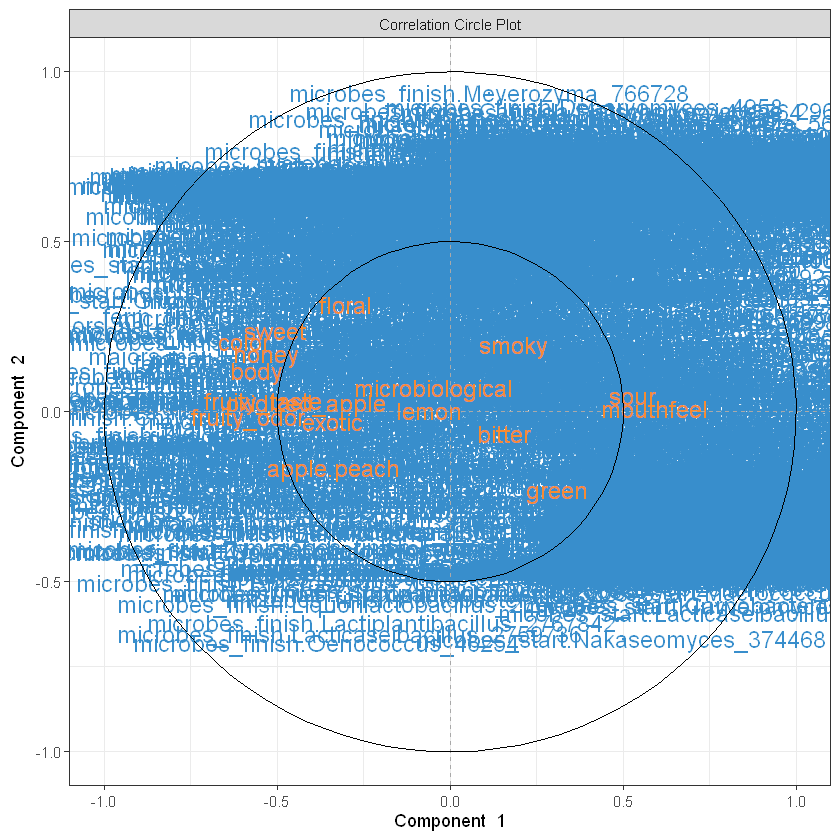

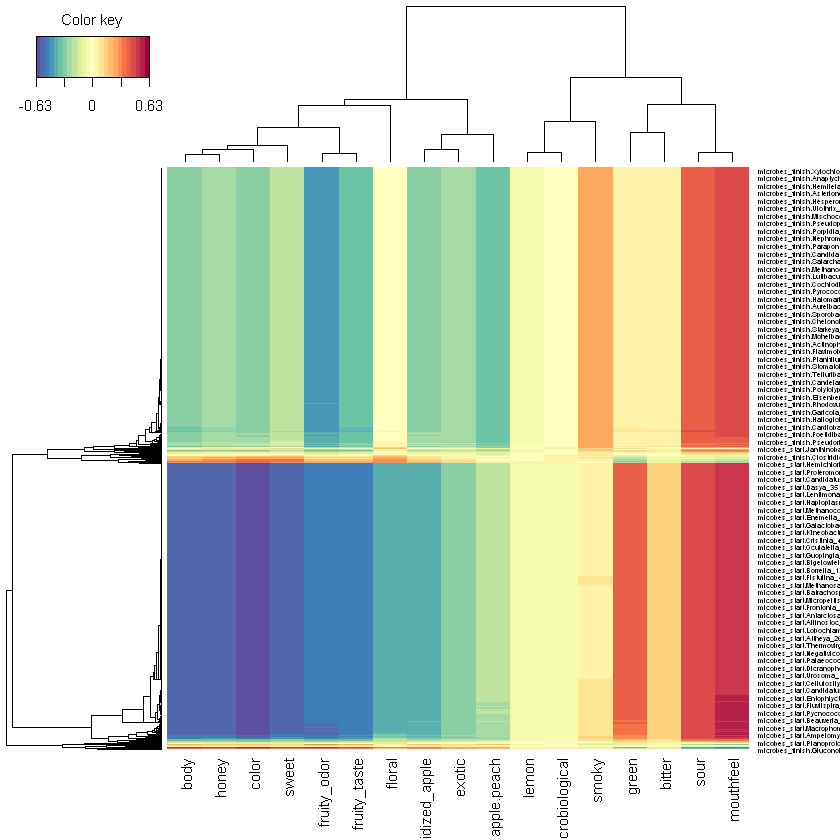

In [55]:
x_combi <- cbind(ferm_start = ferm_start_red, ferm_fin = ferm_finish_red, 
            minors = minors_red, majors = majors_red, 
            thiols = thiols_red, micobes_start = fermentation_onset_red,
            microbes_finish = fermentation_final_red)

spls_result_all_data <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs_red), near.zero.var = TRUE, scale = TRUE)
# spls_result <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs_red), scale = TRUE, mode = "regression")
# spls_result <- spls(X = fermentation_onset_red, Y = as.matrix(df_flavour_avgs_red), scale = TRUE, mode = "regression")

plotIndiv(spls_result_all_data)          # Sample plots
plotVar(spls_result_all_data)            # Variable plots
# plotLoadings(spls_result_all_data)       # Loadings to see important features
cim(spls_result_all_data)


# Here we remove the WGT from the data so we only see the uni fermentation

In [56]:
row.names(fermentation_final_red)
ftir_ferm_start_no_wgt <- subset(ferm_start_red, !grepl("wgt", rownames(ferm_start_red)))
ftir_ferm_final_no_wgt <- subset(ferm_finish_red, !grepl("wgt", rownames(ferm_finish_red)))
minors_no_wgt <- subset(minors_red, !grepl("wgt", rownames(minors_red)))
majors_no_wgt <- subset(majors_red, !grepl("wgt", rownames(majors_red)))
thiols_no_wgt <- subset(thiols_red, !grepl("wgt", rownames(thiols_red)))
fermentation_onset_no_wgt <- subset(fermentation_onset_red, !grepl("wgt", rownames(fermentation_onset_red)))
fermentation_final_no_wgt <- subset(fermentation_final_red, !grepl("wgt", rownames(fermentation_final_red)))
df_flavour_avgs_no_wgt <- subset(df_flavour_avgs_red, !grepl("wgt", rownames(df_flavour_avgs_red)))

[1] "01a"  "01b"  "01c"  "02a"  "02b"  "02c"  "03a"  "03b"  "03c"  "04a" 
[11] "04b"  "04c"  "05a"  "05b"  "05c"  "06a"  "06c"  "07a"  "07b"  "07c" 
[21] "wgt1" "wgt2" "wgt4" "wgt5"

# This snippet we can make closer calculations... 
But inreality it was not really finished

[1] "Cor start_tart - final_tart:   76.2916464575625%"

[1] "Cor start_tart - flav_sour:   62.1497421678694%"

[1] "Cor final_tart - flav_sour:   87.2409473558876%"

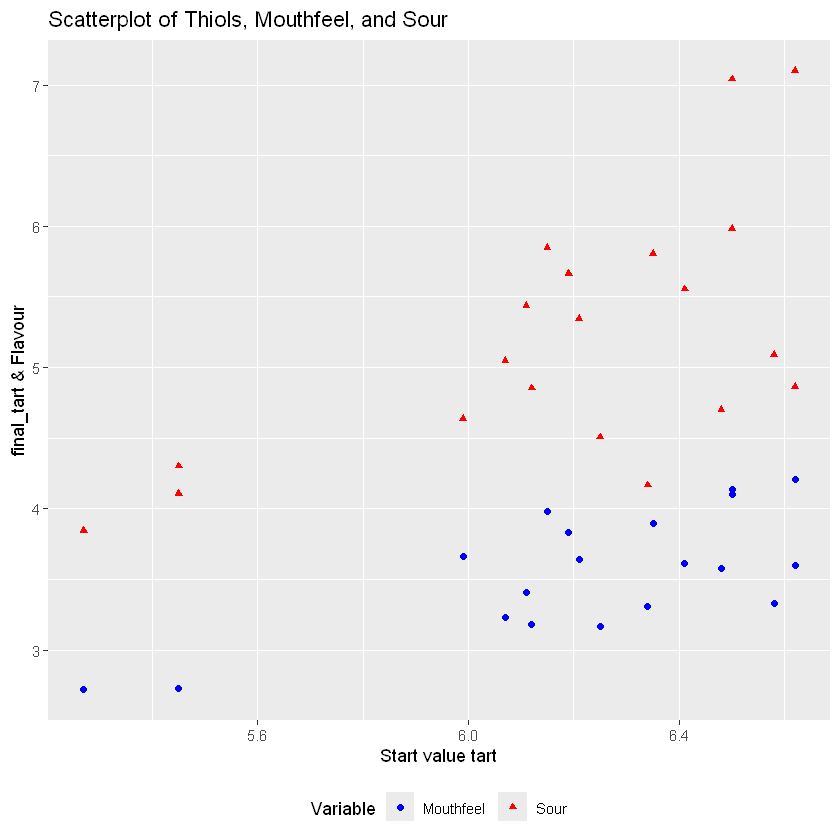

In [57]:
data <- data.frame(
    start_tart = ftir_ferm_start_no_wgt$tart,
    final_tart = ftir_ferm_final_no_wgt$fin_tart,
    sour = df_flavour_avgs_no_wgt$sour
)

# Create the scatterplot with different shapes and a legend
ggplot(data, aes(x = start_tart)) +
    geom_point(aes(y = final_tart, shape = "Mouthfeel"), color = "blue") +
    geom_point(aes(y = sour, shape = "Sour"), color = "red") +
    scale_shape_manual(values = c("Mouthfeel" = 16, "Sour" = 17)) +
    labs(
        title = "Scatterplot of Thiols, Mouthfeel, and Sour",
        x = "Start value tart",
        y = "final_tart & Flavour",
        shape = "Variable"
    )   +
    theme(legend.position = "bottom")

# Calculate the correlations
paste0("Cor start_tart - final_tart:   ", cor(data$start_tart, data$final_tart)*100, "%")
paste0("Cor start_tart - flav_sour:   ", cor(data$start_tart, data$sour)*100, "%")
paste0("Cor final_tart - flav_sour:   ", cor(data$final_tart, data$sour)*100, "%")

In [58]:
fermentation_onset_no_wgt

,Saccharomyces_4930,Hanseniaspora_29832,Ralstonia_48736,Aureobasidium_5579,Pseudomonas_286,Burkholderia_32008,Paraburkholderia_1822464,Bradyrhizobium_374,Acidocella_50709,Botrytis_33196,⋯,Valsaria_338773,Neidium_432550,Zosterodasys_502091,Cyclotrichium_696132,Dictyococcus_889454,Nelsenium_1340027,Clitocella_1522124,Myrmicinosporidium_2820144,Hygrocybe_51006,Dermonema_997601
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01a,85.1388665,10.74882184,1.5337677,1.273187380,0.02678742,0.21173574,0.13023309,0.09263048,0.094869562,0.300123570,⋯,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387,-0.01403387
01b,85.7597023,2.71769529,1.8759031,1.491915753,0.54629115,0.25096602,0.15192904,0.09701982,0.077531138,0.370220065,⋯,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792,-0.01319792
01c,85.1557605,10.65029520,1.1652580,1.286900324,0.21035169,0.17756698,0.09719915,0.33892903,0.076483600,0.283538427,⋯,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948,-0.01402948
02a,5.6321990,85.43353746,5.9411219,0.192694232,0.38023345,0.74722086,0.49511967,0.36282085,0.256081010,0.052101349,⋯,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805,-0.01412805
02b,38.5491723,75.68863145,11.8981847,0.626844816,0.87373691,1.59953642,1.02918863,0.88800412,0.665565694,0.185873104,⋯,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938,-0.01952938
02c,15.2252451,83.03918332,14.4878509,0.494628628,0.70034107,1.77444901,1.16936945,0.86878777,0.635105409,0.129303017,⋯,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475,-0.01775475
03a,85.8273490,0.41786251,1.1935948,0.086501225,0.37789482,0.14873054,0.08534870,0.06181455,0.057375317,0.069304178,⋯,-0.01237998,-0.01237998,-0.01237998,-0.01237998,-0.01237998,-0.01237998,-0.01237998,-0.01237998,-0.01237998,-0.01237998
03b,85.1709435,10.36468639,2.5956258,0.020551926,0.29883205,0.31525656,0.20124702,0.17343748,0.165327161,0.002923292,⋯,-0.01385162,-0.01385162,-0.01385162,-0.01385162,-0.01385162,-0.01385162,-0.01385162,-0.01385162,-0.01385162,-0.01385162
03c,61.6096850,59.66514588,3.4373480,-0.007400227,0.14968035,0.36296542,0.24204362,0.19954044,0.114972964,-0.014335620,⋯,-0.01741222,-0.01741222,-0.01741222,-0.01741222,-0.01741222,-0.01741222,-0.01741222,-0.01741222,-0.01741222,-0.01741222


[1] 3.6 4.3 4.6 2.4 3.2 3.7 2.0 1.4 1.5 2.9 3.1 2.2 2.8 1.8 2.5 4.0 4.8 3.9 4.0
[20] 3.3

[1] 5.107500 5.453846 4.822500 4.400000 4.282500 3.845000 4.352542 3.765000
 [9] 4.347500 5.197500 4.995000 5.372500 5.520513 6.377500 6.660000 4.790000
[17] 4.527500 5.538333 4.445000 4.902500

[1] 4.637500 5.553846 5.347500 3.845000 4.302500 4.107500 5.089831 4.167500
 [9] 5.437500 5.805000 5.662500 5.850000 5.982051 7.040000 7.100000 4.865000
[17] 4.700000 5.048333 4.852500 4.507500

[1] "Cor thiol_FFT - flav_mouthfeel:   -3.82602663935084%"

[1] "Cor thol_FFT - flav_sour:   -24.053835169541%"

[1] "Cor flav_mouthfeel - flav_sour:   86.019344910138%"

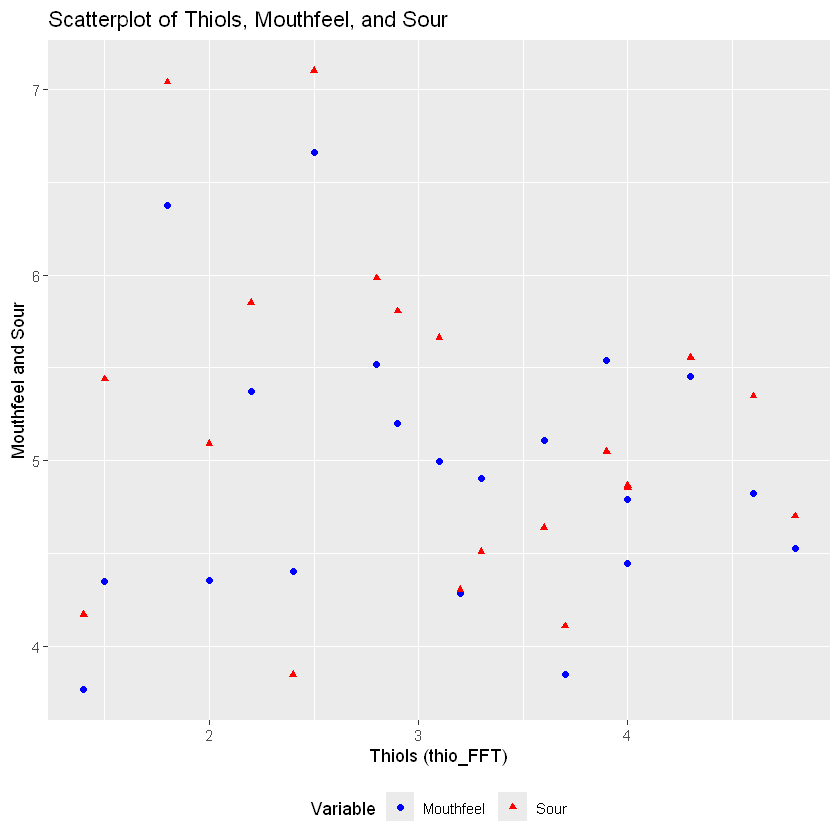

In [59]:
thiols_no_wgt$thio_FFT
df_flavour_avgs_no_wgt$mouthfeel
df_flavour_avgs_no_wgt$sour


data <- data.frame(
  thio_FFT = thiols_no_wgt$thio_FFT,
  mouthfeel = df_flavour_avgs_no_wgt$mouthfeel,
  sour = df_flavour_avgs_no_wgt$sour
)

# Create the scatterplot with different shapes and a legend
ggplot(data, aes(x = thio_FFT)) +
  geom_point(aes(y = mouthfeel, shape = "Mouthfeel"), color = "blue") +
  geom_point(aes(y = sour, shape = "Sour"), color = "red") +
  scale_shape_manual(values = c("Mouthfeel" = 16, "Sour" = 17)) +
  labs(
    title = "Scatterplot of Thiols, Mouthfeel, and Sour",
    x = "Thiols (thio_FFT)",
    y = "Mouthfeel and Sour",
    shape = "Variable"
  ) +
  theme(legend.position = "bottom")

# Calculate the correlations
paste0("Cor thiol_FFT - flav_mouthfeel:   ", cor(data$thio_FFT, data$mouthfeel)*100, "%")
paste0("Cor thol_FFT - flav_sour:   ", cor(data$thio_FFT, data$sour)*100, "%")
paste0("Cor flav_mouthfeel - flav_sour:   ", cor(data$mouthfeel, data$sour)*100, "%")

In [60]:
cor.test(minors_no_wgt$min_X..Terpineol, df_flavour_avgs_no_wgt$bitter, method = "spearman")
cor.test(minors_no_wgt$min_X..Terpineol, df_flavour_avgs_no_wgt$bitter, method = "spearman")
testing <- cor.test(minors_no_wgt$min_X..Terpineol, df_flavour_avgs_no_wgt$bitter, method = "spearman")


	Spearman's rank correlation rho

data:  minors_no_wgt$min_X..Terpineol and df_flavour_avgs_no_wgt$bitter
S = 674, p-value = 0.02866
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.4932331 



	Spearman's rank correlation rho

data:  minors_no_wgt$min_X..Terpineol and df_flavour_avgs_no_wgt$bitter
S = 674, p-value = 0.02866
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.4932331 


In [61]:
# colnames(x_combi_no_wgt)
cor.test(minors_no_wgt$min_X..Terpineol, df_flavour_avgs_no_wgt$bitter, method = "spearman")



	Spearman's rank correlation rho

data:  minors_no_wgt$min_X..Terpineol and df_flavour_avgs_no_wgt$bitter
S = 674, p-value = 0.02866
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.4932331 


In [62]:
testing$p.value
testing$estimate

[1] 0.02866112

rho 
0.4932331

In [63]:
# cor.test(x_combi_no_wgt[, "minors.min_X..Terpineol"], df_flavour_avgs_no_wgt[, "bitter"], method = "spearman")
# # x_combi_no_wgt$minors.min_X..Terpineol

# Here we create the correlations and flavours and everything

In [64]:
x_combi_no_wgt <- cbind(ferm_start = ftir_ferm_start_no_wgt, ferm_fin = ftir_ferm_final_no_wgt, 
            minors = minors_no_wgt, majors = majors_no_wgt, 
            thiols = thiols_no_wgt, micobes_start = fermentation_onset_no_wgt,
            microbes_finish = fermentation_final_no_wgt)

In [65]:
combinations_df <- expand.grid(colnames(x_combi_no_wgt), colnames(df_flavour_avgs_no_wgt))

In [66]:
# combinations_df <- head(combinations_df, 1000)
# combinations_df

Warning message in Check.entry.pls(X, Y, ncomp, keepX, keepY, mode = mode, scale = scale, :
"Zero- or near-zero variance predictors.
 Reset
            predictors matrix to not near-zero variance predictors.

            See $nzv for problematic predictors."


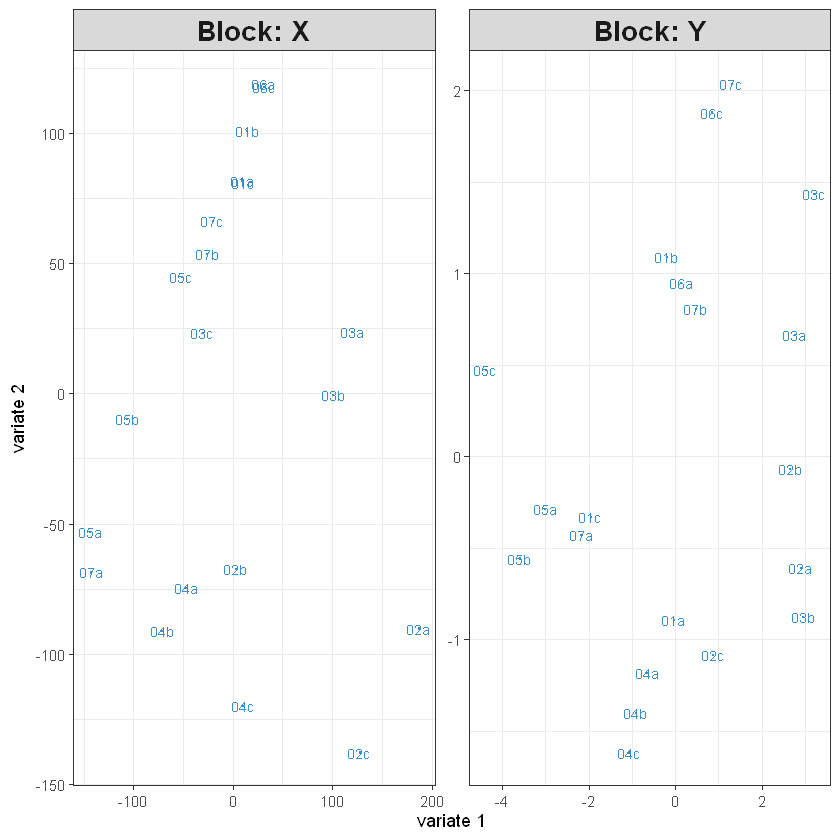

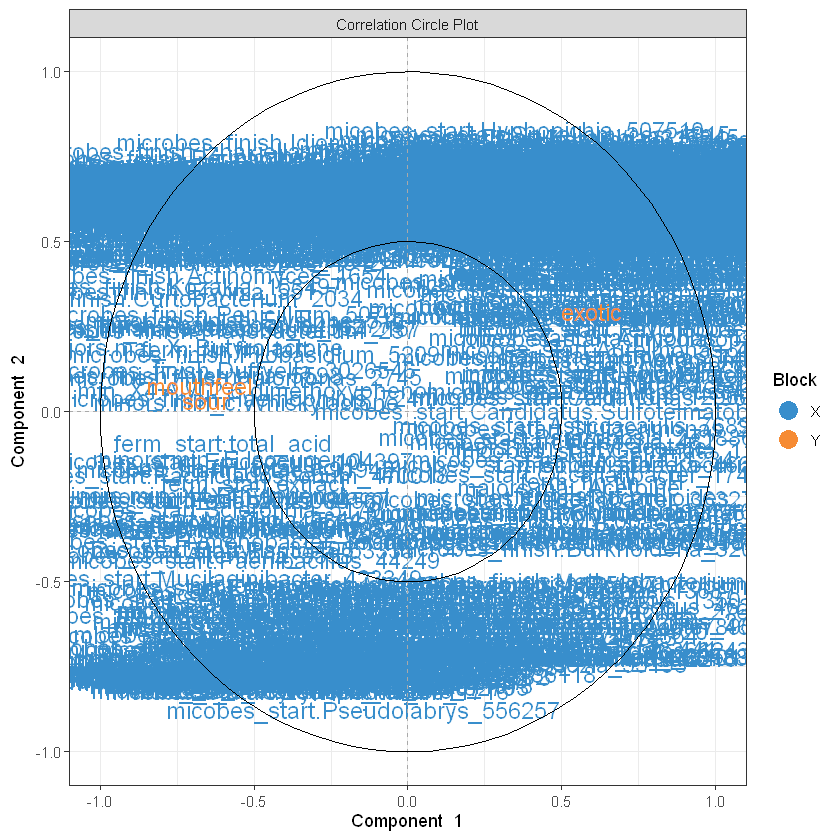

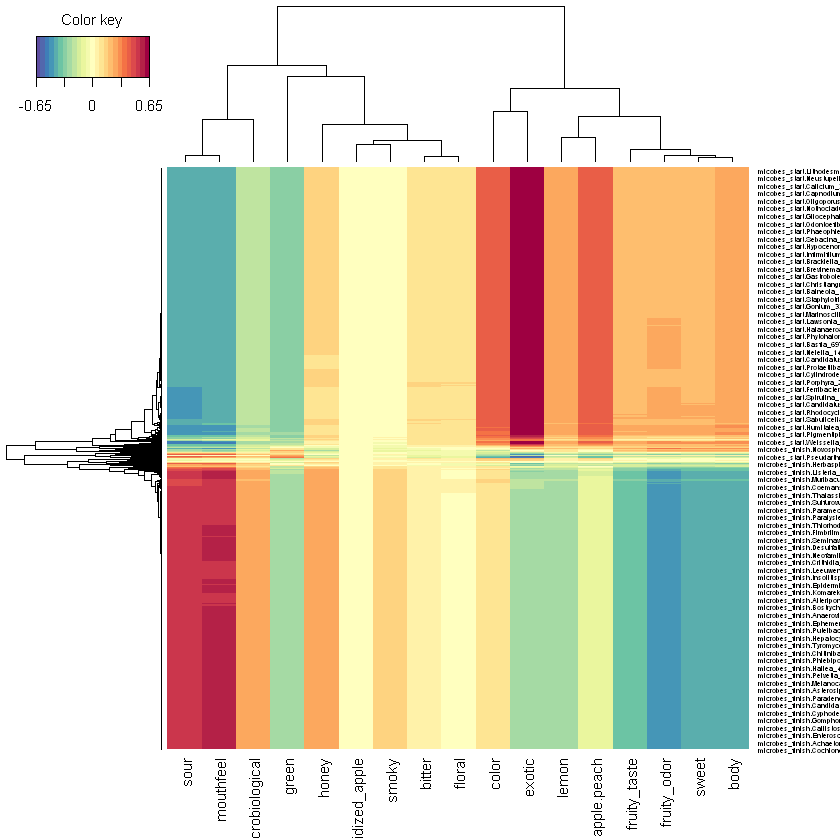

In [67]:


spls_result_all_data_no_wgt <- spls(X = x_combi_no_wgt, Y = as.matrix(df_flavour_avgs_no_wgt), near.zero.var = TRUE, scale = TRUE)

plotIndiv(spls_result_all_data_no_wgt)          # Sample plots
plotVar(spls_result_all_data_no_wgt, legend = TRUE, cutoff = 0.50)            # Variable plots
# plotLoadings(spls_result_all_data_no_wgt)       # Loadings to see important features
cim(spls_result_all_data_no_wgt)

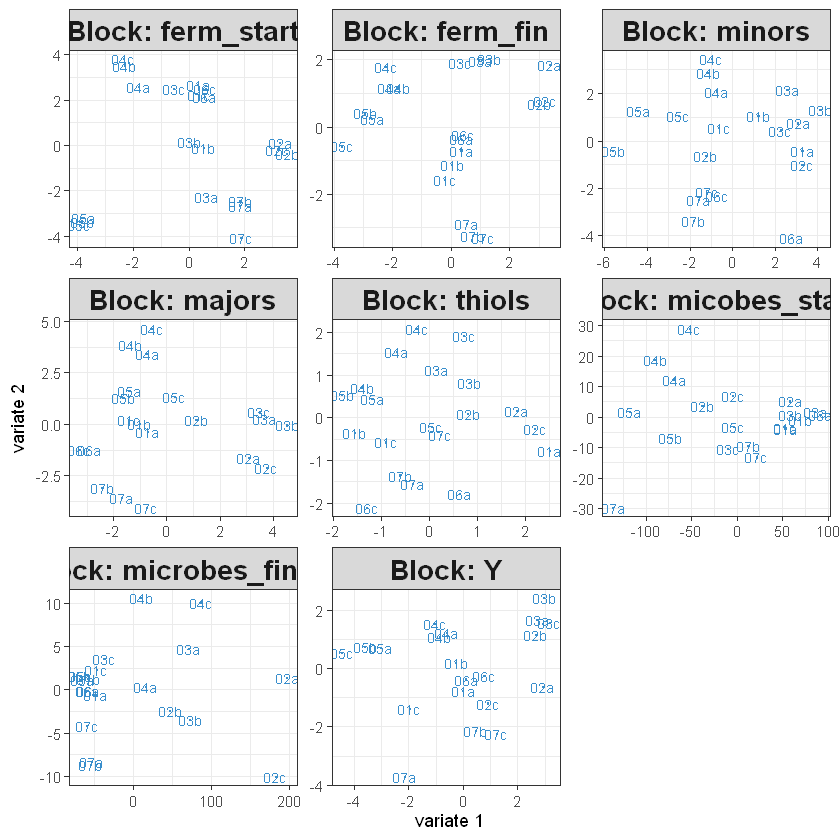

In [68]:
x <- list(ferm_start = ftir_ferm_start_no_wgt, ferm_fin = ftir_ferm_final_no_wgt, 
            minors = minors_no_wgt, majors = majors_no_wgt, 
            thiols = thiols_no_wgt, micobes_start = fermentation_onset_no_wgt,
            microbes_finish = fermentation_final_no_wgt)




block.pls.result_all_data_no_wgt <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_no_wgt), design = "full", mode = "regression", near.zero.var = TRUE, ncomp = 3)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "canonical", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "invariant", near.zero.var = TRUE)
# block.pls.result <- block.pls(X = x, Y = as.matrix(df_flavour_avgs_red), design = "full", mode = "classic", near.zero.var = TRUE)

plotIndiv(block.pls.result_all_data_no_wgt) # plot the samples
# plotVar(block.pls.result_all_data_no_wgt, legend = TRUE,
# cutoff = 0.0, style = "3d", ) # plot the variables

In [69]:
# circosPlot(block.pls.result_all_data_no_wgt)

In [70]:
block.pls.result_all_data_no_wgt


Call:
 block.pls(X = x, Y = as.matrix(df_flavour_avgs_no_wgt), ncomp = 3, design = "full", mode = "regression", near.zero.var = TRUE) 

 sGCCA with 3 components on block 1 named ferm_start 
 sGCCA with 3 components on block 2 named ferm_fin 
 sGCCA with 3 components on block 3 named minors 
 sGCCA with 3 components on block 4 named majors 
 sGCCA with 3 components on block 5 named thiols 
 sGCCA with 3 components on block 6 named micobes_start 
 sGCCA with 3 components on block 7 named microbes_finish 
 sGCCA with 3 components on block 8 named Y 

 Dimension of block 1 is  20 17 
 Dimension of block 2 is  20 17 
 Dimension of block 3 is  20 34 
 Dimension of block 4 is  20 28 
 Dimension of block 5 is  20 6 
 Dimension of block 6 is  20 7371 
 Dimension of block 7 is  20 7371 
 Dimension of block 8 is  20 17 

 Selection of 17 17 17 variables on each of the sGCCA components on the block 1 
 Selection of 17 17 17 variables on each of the sGCCA components on the block 2 
 Selection of 3

In [71]:
x_combi <- cbind(microbes_finish = fermentation_final_no_wgt)

spls_result_microbe_finish <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs_no_wgt), near.zero.var = TRUE, scale = TRUE)

# plotIndiv(spls_result_microbe_finish)          # Sample plots
# plotVar(spls_result_microbe_finish, legend = TRUE, cutoff = 0.50)            # Variable plots
# cim(spls_result_microbe_finish, cutoff=0.5)



In [72]:
x_combi <- cbind(micobes_start = fermentation_onset_no_wgt,
            microbes_finish = fermentation_final_no_wgt)

spls_result_microbe_start_finish <- spls(X = x_combi, Y = as.matrix(df_flavour_avgs_no_wgt), near.zero.var = TRUE, scale = TRUE)

# plotIndiv(spls_result_microbe_start_finish)          # Sample plots
# plotVar(spls_result_microbe_start_finish, legend = TRUE, cutoff = 0.50)            # Variable plots
# plotLoadings(spls_result_microbe_start_finish, ndisplay = 20)       # Loadings to see important features
# cim(spls_result_microbe_start_finish)

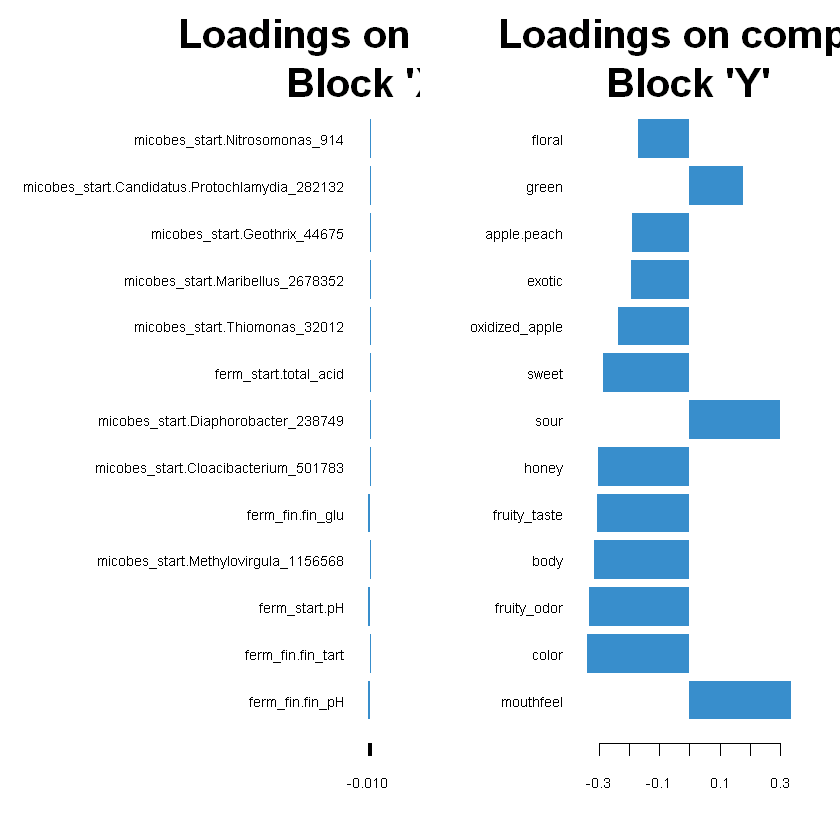

In [73]:
plotLoadings(spls_result_all_data, ndisplay = 13)

In [74]:
spls_result_microbe_start_finish$variates$X

,comp1,comp2
01a,9.127657,81.9152193
01b,14.110779,100.8047570
01c,10.082746,81.1128405
02a,186.562082,-90.1763267
02b,2.342661,-67.4868649
02c,127.389476,-137.8654678
03a,119.428354,23.6471254
03b,100.315548,-0.1767125
03c,-30.794305,23.4751584
04a,-46.928418,-74.3674527


In [75]:
print("Only FTIR correlation")
cor(spls_result_ftir_only$variates$X, spls_result_ftir_only$variates$Y)
print("Ftir + Metabolomics correlation")
cor(spls_result_ftir_metabolomics$variates$X, spls_result_ftir_metabolomics$variates$Y)
print("FTIR + Metabolomics + Metagenomics start correlation")
cor(spls_result_ftir_metabol_metagen_start$variates$X, spls_result_ftir_metabol_metagen_start$variates$Y)
print("FTIR + Metabolomics + Metagenomics start & end correlation")
cor(spls_result_all_data$variates$X, spls_result_all_data$variates$Y)
print("FTIR + Metabolomics + Metagenomics start & end correlation, no WGT data")
cor(spls_result_all_data_no_wgt$variates$X, spls_result_all_data_no_wgt$variates$Y)
print("Metagenomics end correlation, no WGT data")
cor(spls_result_microbe_finish$variates$X, spls_result_microbe_finish$variates$Y)
print("Metagenomics start & end correlation, no WGT data")
cor(spls_result_microbe_start_finish$variates$X, spls_result_microbe_start_finish$variates$Y)


[1] "Only FTIR correlation"


,comp1,comp2
comp1,0.86652655,1.954918e-19
comp2,0.09270218,6.577609e-01


[1] "Ftir + Metabolomics correlation"


,comp1,comp2
comp1,0.8487713,-1.207939e-17
comp2,-0.1390632,9.026045e-01


[1] "FTIR + Metabolomics + Metagenomics start correlation"


,comp1,comp2
comp1,0.6863347,-7.484505e-17
comp2,0.1416399,7.964779e-01


... (4 outputs left out)

[1] "Metagenomics end correlation, no WGT data"


,comp1,comp2
comp1,0.6362586,-5.91293e-17
comp2,0.1224248,7.65764e-01


[1] "Metagenomics start & end correlation, no WGT data"


,comp1,comp2
comp1,0.6947678,1.076516e-16
comp2,0.0086873,7.326739e-01


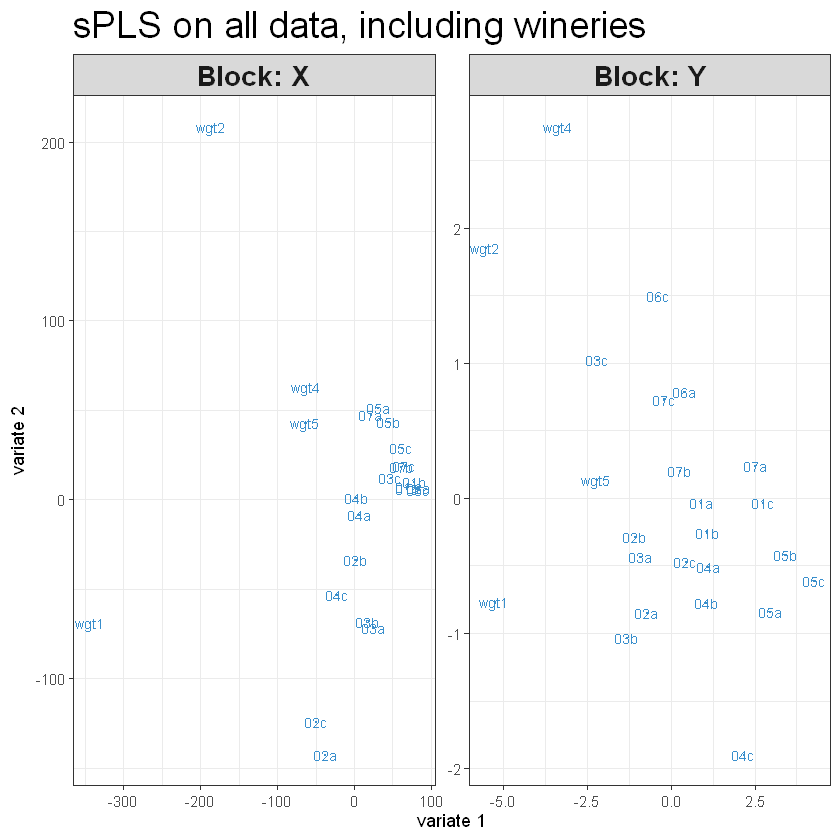

In [76]:
plotIndiv(spls_result_all_data,   # plot in joint subspace, 
          #   rep.space = 'XY-variate',
          title = 'sPLS on all data, including wineries')

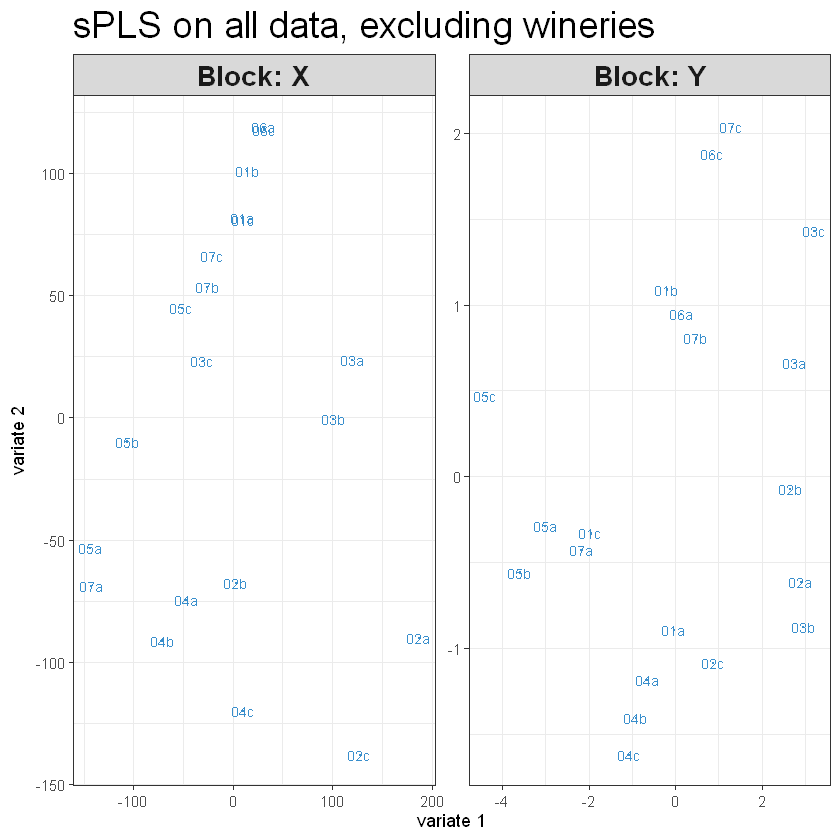

In [77]:
plotIndiv(spls_result_all_data_no_wgt,   # plot in joint subspace, 
          #   rep.space = 'XY-variate',
          title = 'sPLS on all data, excluding wineries')

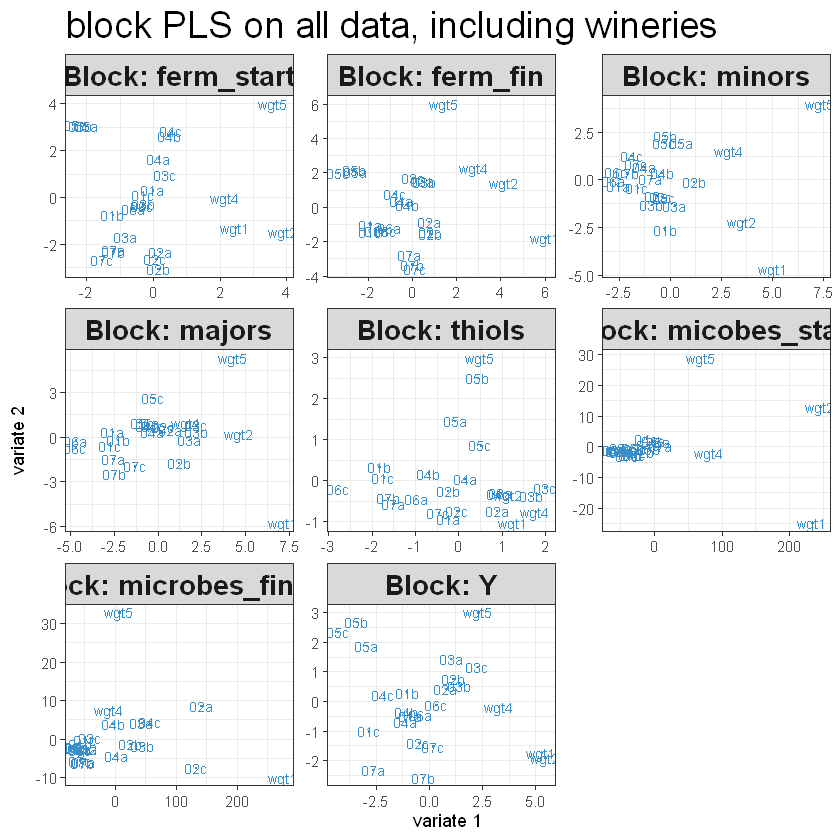

In [78]:
plotIndiv(block.pls.result_all_data,
        title = 'block PLS on all data, including wineries')

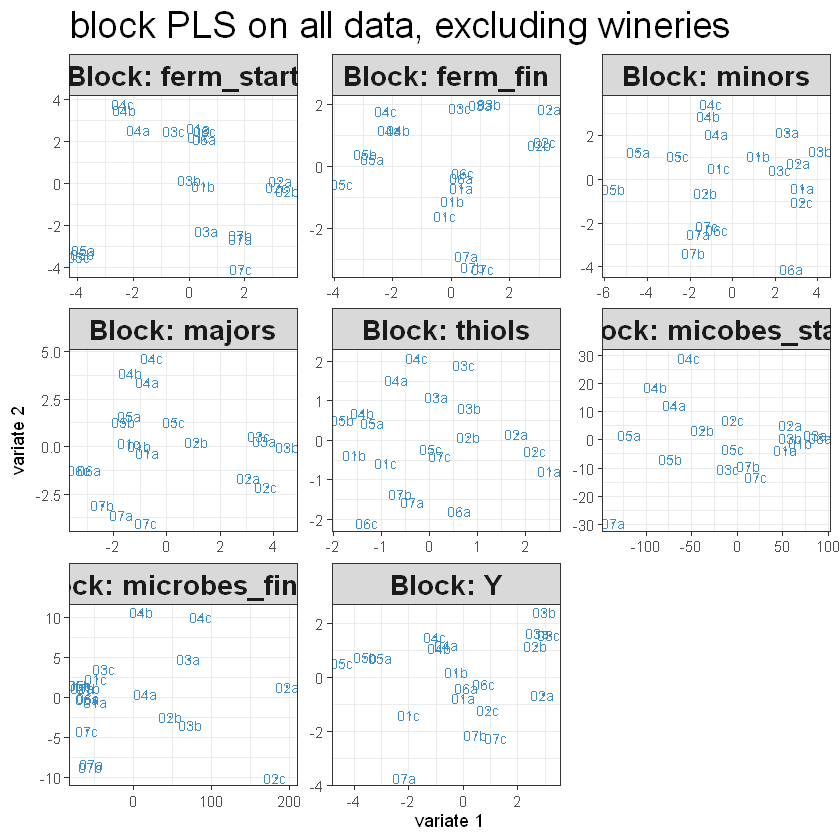

In [79]:
plotIndiv(block.pls.result_all_data_no_wgt, 
        title = 'block PLS on all data, excluding wineries')

In [80]:
block.pls.result_all_data_no_wgt


Call:
 block.pls(X = x, Y = as.matrix(df_flavour_avgs_no_wgt), ncomp = 3, design = "full", mode = "regression", near.zero.var = TRUE) 

 sGCCA with 3 components on block 1 named ferm_start 
 sGCCA with 3 components on block 2 named ferm_fin 
 sGCCA with 3 components on block 3 named minors 
 sGCCA with 3 components on block 4 named majors 
 sGCCA with 3 components on block 5 named thiols 
 sGCCA with 3 components on block 6 named micobes_start 
 sGCCA with 3 components on block 7 named microbes_finish 
 sGCCA with 3 components on block 8 named Y 

 Dimension of block 1 is  20 17 
 Dimension of block 2 is  20 17 
 Dimension of block 3 is  20 34 
 Dimension of block 4 is  20 28 
 Dimension of block 5 is  20 6 
 Dimension of block 6 is  20 7371 
 Dimension of block 7 is  20 7371 
 Dimension of block 8 is  20 17 

 Selection of 17 17 17 variables on each of the sGCCA components on the block 1 
 Selection of 17 17 17 variables on each of the sGCCA components on the block 2 
 Selection of 3

In [81]:
# spls_result_all_data_no_wgt

In [82]:
# selectVar(spls_result_all_data_no_wgt)

In [83]:
# selectVar(block.pls.result_all_data_no_wgt)

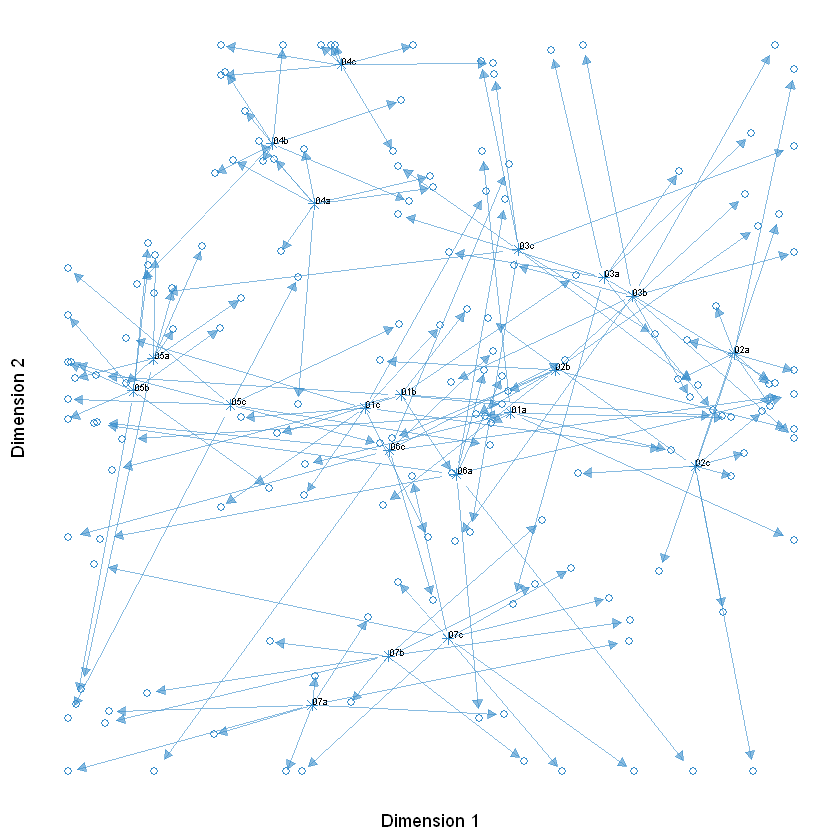

In [84]:
plotArrow(block.pls.result_all_data_no_wgt, ind.names = TRUE)

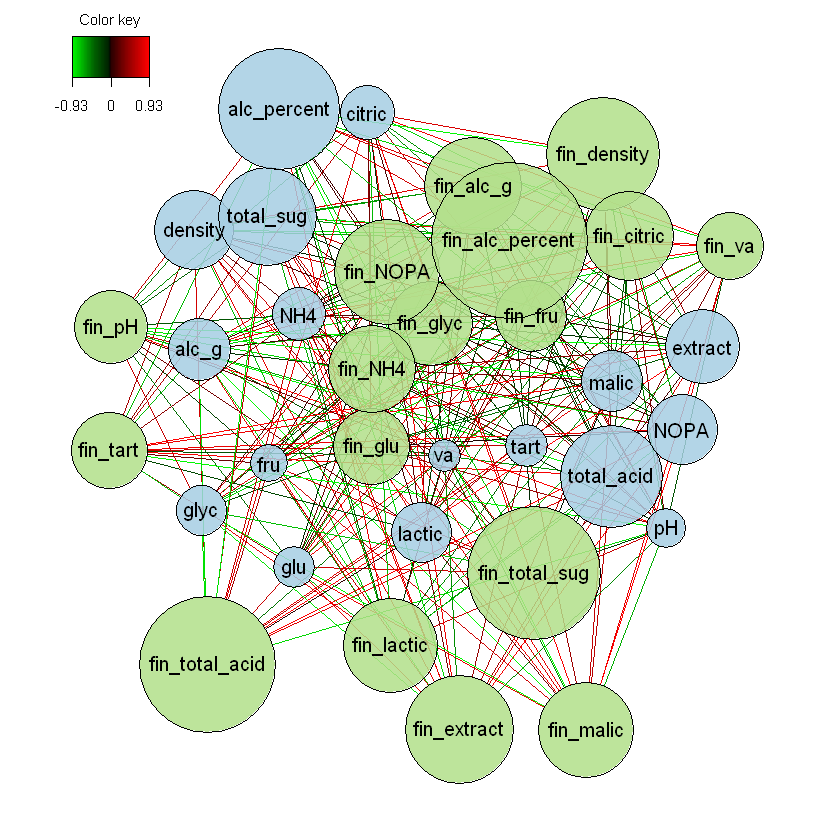

In [85]:
network(block.pls.result_all_data_no_wgt)

In [86]:
# network(spls_result_all_data_no_wgt)

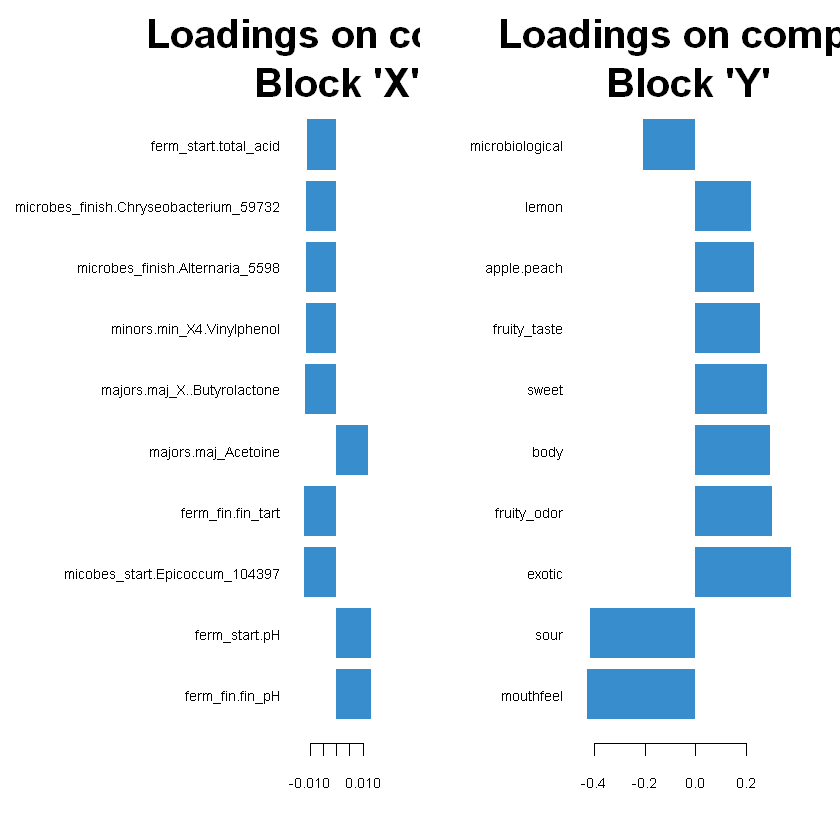

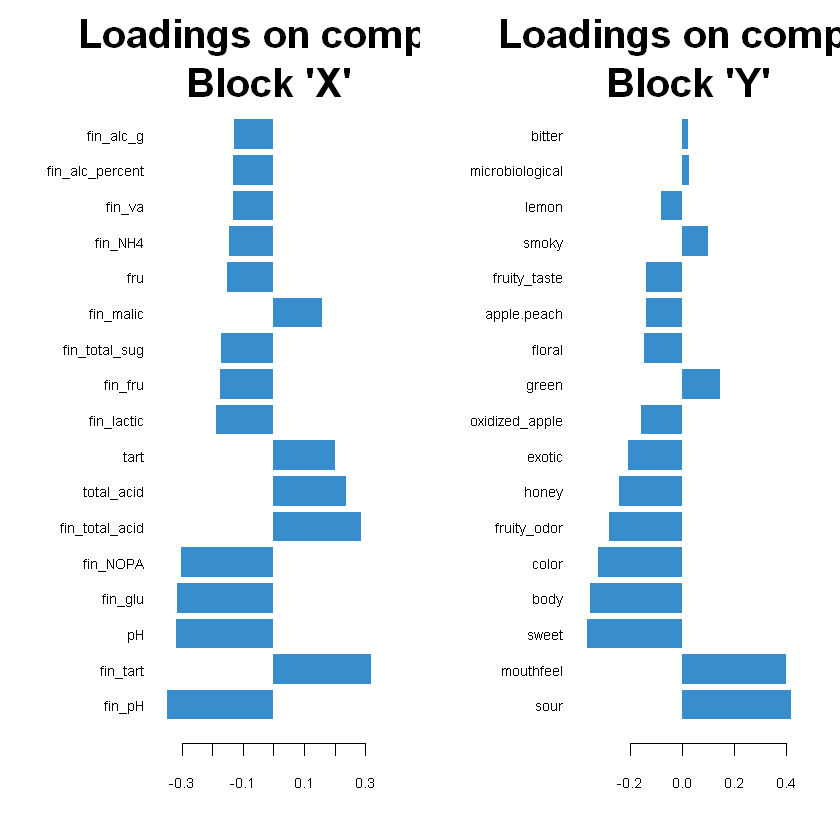

In [87]:
# spls_result_all_data_no_wgt$loadings.star
plotLoadings(spls_result_all_data_no_wgt, ndisplay = 10, comp = 1, contrib = "max", method = "mean")       # Loadings to see important features
plotLoadings(spls_result_ftir_only, ndisplay = 17, comp = 1, contrib = "max", method = "mean")       # Loadings to see important features


In [88]:
# # spls_result_all_data_no_wgt

# plotIndiv(spls_result_all_data_no_wgt, rep.space = 'XY-variate', ind.names = FALSE,
# group = as.matrix(df_flavour_avgs_no_wgt), 
# pch = 20, main = 'Both Gene expression and Clinical subspaces',
# legend = TRUE)

In [89]:
spls_result_ftir_only$loadings


,comp1,comp2
density,-0.096082114,-0.179082901
alc_g,0.021844769,0.210697646
total_sug,-0.121171617,-0.157869565
glu,-0.107930200,-0.173063318
fru,-0.152676233,-0.111219994
total_acid,0.236814045,-0.191226301
pH,-0.319376934,0.102344575
va,-0.094073466,0.007555809
tart,0.199880308,-0.071889295
lactic,-0.089643580,-0.010097393


In [90]:
block.pls.result_all_data_no_wgt$loadings

,comp1,comp2,comp3
density,-0.037661170,0.30312609,0.067529489
alc_g,0.069839533,-0.24956320,-0.382859097
total_sug,0.002807893,0.32433904,0.015711840
glu,-0.010313391,0.31931882,0.030717521
fru,0.039882137,0.31705388,-0.010829537
total_acid,-0.445726782,-0.07317491,-0.094991972
pH,0.453810497,0.15857575,-0.214447948
va,0.212527816,-0.10799325,0.212389787
tart,-0.344487368,-0.18029849,-0.380963530
lactic,0.276809588,0.32566097,-0.283646766


In [91]:
# spls_result_ftir_only$loadings$X[order(spls_result_ftir_only$loadings$X[, 1]), ]
# spls_result_ftir_only$loadings$Y[order(spls_result_ftir_only$loadings$Y[, 1]), ]
# spls_result_all_data_no_wgt$loadings$X[order(spls_result_all_data_no_wgt$loadings$X[, 1]), ]
# # spls_result_all_data_no_wgt$loadings$Y[order(spls_result_all_data_no_wgt$loadings$Y[, 1]), ]
spls_result_microbe_start_finish$loadings$X[order(spls_result_microbe_start_finish$loadings$X[, 1]), ]
spls_result_microbe_start_finish$loadings$Y[order(spls_result_microbe_start_finish$loadings$Y[, 1]), ]
# spls_result_all_data_no_wgt$loadings$X

,comp1,comp2
micobes_start.Epicoccum_104397,-0.012451173,-0.0037006895
microbes_finish.Alternaria_5598,-0.011527830,0.0005602043
microbes_finish.Chryseobacterium_59732,-0.011406406,0.0047692305
microbes_finish.Pedobacter_84567,-0.011069333,0.0013167242
micobes_start.Puia_2045098,-0.010930380,-0.0029142504
micobes_start.Botryotinia_40558,-0.010848247,-0.0059106993
micobes_start.Pedobacter_84567,-0.010790674,-0.0038184555
microbes_finish.Curtobacterium_2034,-0.010703341,0.0027666095
microbes_finish.Erwinia_551,-0.010701150,0.0020240988
microbes_finish.Kozakia_153497,-0.010679971,0.0046605890


,comp1,comp2
mouthfeel,-0.42662266,0.098283878
sour,-0.41592855,0.042323393
microbiological,-0.20968554,0.014707507
smoky,-0.06929480,0.141673351
honey,-0.06797182,0.367522688
green,-0.02576182,-0.512360338
oxidized_apple,-0.01487019,-0.001307713
bitter,0.02489010,0.176913118
floral,0.04465300,0.142475166
color,0.11998720,0.480433407


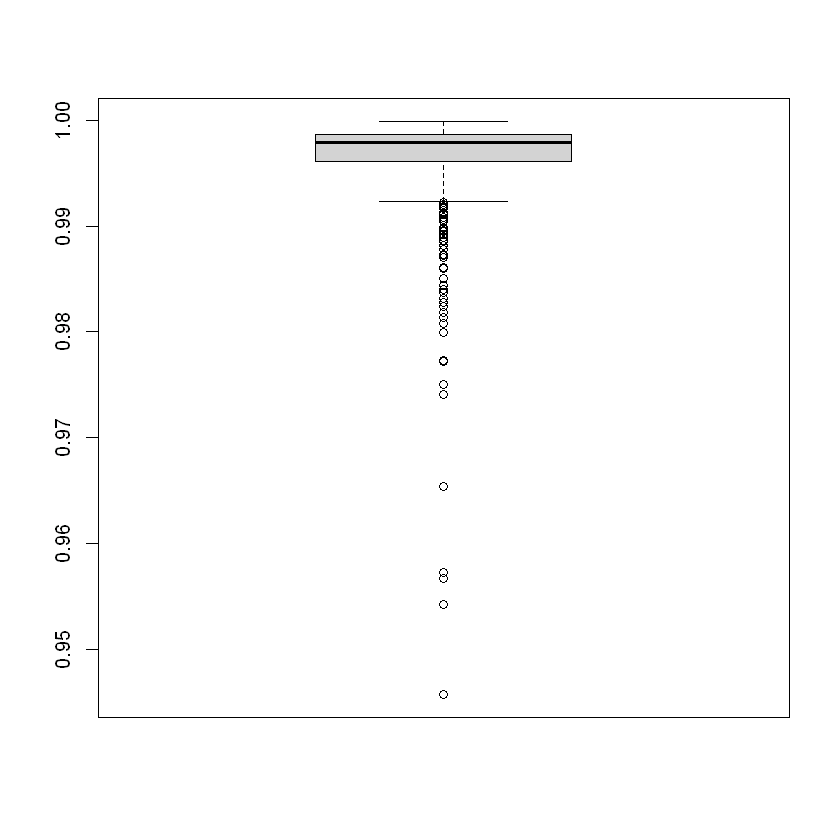

In [92]:
alpha_div = read.csv("alpha_div_genus.csv", header = TRUE, sep=",", row.names = "samples")
boxplot(alpha_div$GiniDominance)


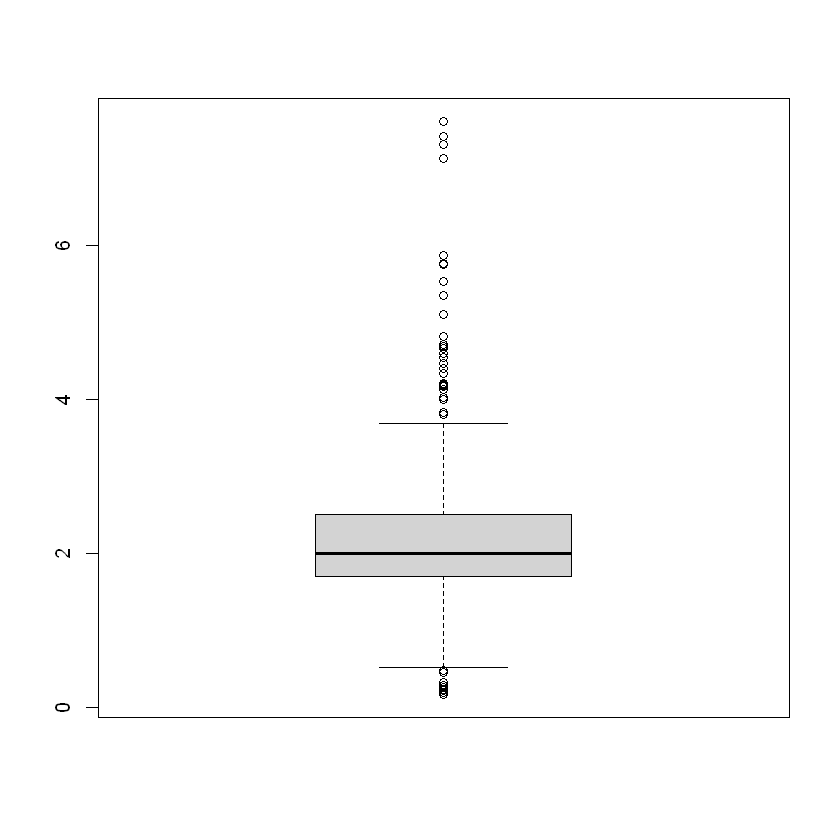

In [93]:
boxplot(alpha_div$ShannonDiversity)


In [94]:
colnames(minors_no_wgt) <- gsub("\\.", "_", colnames(minors_no_wgt))
colnames(majors_no_wgt) <- gsub("\\.", "_", colnames(majors_no_wgt))

x_combi_no_wgt <- cbind(ferm_start = ftir_ferm_start_no_wgt, ferm_fin = ftir_ferm_final_no_wgt, 
            minors = minors_no_wgt, majors = majors_no_wgt, 
            thiols = thiols_no_wgt, micobes_start = fermentation_onset_no_wgt,
            microbes_finish = fermentation_final_no_wgt)

            
combinations_df <- expand.grid(colnames(x_combi_no_wgt), colnames(df_flavour_avgs_no_wgt))
# df_flavour_avgs_no_wgt

In [95]:
# Debugging section

# colnames(x_combi_no_wgt)[grep("^min", colnames(x_combi_no_wgt))]
# fermentation_onset_no_wgt
# minors_no_wgt
# majors_no_wgt
# thiols_no_wgt

# Debugging section

In [94]:
# full_mod <- lm(df_flavour_avgs_no_wgt ~ ftir_ferm_start_no_wgt + ftir_ferm_final_no_wgt + 
#                 minors_no_wgt + majors_no_wgt + thiols_no_wgt + fermentation_onset_no_wgt + 
#                 fermentation_final_no_wgt, data = x_combi_no_wgt)
# summary(full_mod)

# Here we correlate all factors vs all flavours. 
This results in ~250.000 results. Takes a while to write, loads of overhead.

Using the AMD 6900HX processor it takes ~30 minutes to perform, with ending in
a crash of the program, kernel keeps being busy after writing the file. 

If you want to run, uncomment one of the two blocks below. 

Top one calculates sterile, bottom one calculates all.

AUGUST UPDATE!
So apparently when you normalise the data, it does actually run fine and 
finishes normally. Un- normalized, it's hell and gives different results.

In [ ]:
get_correlation <- function(var1, var2) {
    cor_result <- cor.test( x_combi_no_wgt[, var1], 
                            df_flavour_avgs_no_wgt[, var2],
                            method = 'spearman')



    data.frame( factor = var1,
                flavour = var2,
                correlation = cor_result$estimate, 
                p_value = cor_result$p.value,
                sum_factor = sum(x_combi_no_wgt[, var1]))
}

correlations <- do.call(rbind, 
                        apply(combinations_df, 1, function(row) {
                            get_correlation(row["Var1"], row["Var2"])
                        }))

print("Calculating P- values...")
# correlations
correlations$adjusted_p_value <- p.adjust(correlations$p_value, method = "fdr")

print("Starting to write table...")
write.table(correlations, sep = "\t", file = "Correlations_PValue_MultiOmics_NoWGT_Fixed_31072025.tsv")
# write.table(t(euclidian_distance), sep = "\t", file = "euclidian_distances_xy.tsv")
print("Done! I hope you get to see this one...")

In [96]:
# x_combi_reduced <- cbind(ferm_start = ferm_start_red, ferm_fin = ferm_finish_red, 
#             minors = minors_red, majors = majors_red, 
#             thiols = thiols_red, micobes_start = fermentation_onset_red,
#             microbes_finish = fermentation_final_red)

# # df_flavour_avgs_red

# get_correlation <- function(var1, var2) {
#     cor_result <- cor.test( x_combi_reduced[, var1], 
#                             df_flavour_avgs_red[, var2],
#                             method = 'spearman')

#     data.frame( factor = var1,
#                 flavour = var2,
#                 correlation = cor_result$estimate, 
#                 p_value = cor_result$p.value,
#                 sum_factor = sum(x_combi_reduced[, var1]))
#                 # sum_factor = sum(x_combi_reduced[, var1])
# }

# correlations <- do.call(rbind, 
#                         apply(combinations_df, 1, function(row) {
#                             get_correlation(row["Var1"], row["Var2"])
#                         }))

# # correlations
# correlations$adjusted_p_value <- p.adjust(correlations$p_value, method = "fdr")
# write.table(correlations, sep = "\t", file = "Correlations_PValue_MultiOmics_including_WGT.tsv")
# # write.table(t(euclidian_distance), sep = "\t", file = "euclidian_distances_xy_including_wgt.tsv")
# # rm(correlations)

In [97]:
# df_list_all <- list(ferm_start_red, ferm_finish_red, 
#             minors_red, majors_red, 
#             thiols_red, fermentation_onset_red,
#             fermentation_final_red, df_flavour_avgs_red)